# Context

The stock market has consistently proven to be a good place to invest in and save for the future. There are a lot of compelling reasons to invest in stocks. It can help in fighting inflation, create wealth, and also provides some tax benefits. Good steady returns on investments over a long period of time can also grow a lot more than seems possible. Also, thanks to the power of compound interest, the earlier one starts investing, the larger the corpus one can have for retirement. Overall, investing in stocks can help meet life's financial aspirations.

It is important to maintain a diversified portfolio when investing in stocks in order to maximise earnings under any market condition. Having a diversified portfolio tends to yield higher returns and face lower risk by tempering potential losses when the market is down. It is often easy to get lost in a sea of financial metrics to analyze while determining the worth of a stock, and doing the same for a multitude of stocks to identify the right picks for an individual can be a tedious task. By doing a cluster analysis, one can identify stocks that exhibit similar characteristics and ones which exhibit minimum correlation. This will help investors better analyze stocks across different market segments and help protect against risks that could make the portfolio vulnerable to losses.




# Objective

Trade&Ahead is a financial consultancy firm who provide their customers with personalized investment strategies. They have hired you as a Data Scientist and provided you with data comprising stock price and some financial indicators for a few companies listed under the New York Stock Exchange. They have assigned you the tasks of analyzing the data, grouping the stocks based on the attributes provided, and sharing insights about the characteristics of each group.

# Data Dictionary

- Ticker Symbol: An abbreviation used to uniquely identify publicly traded shares of a particular stock on a particular stock market
- Company: Name of the company
- GICS Sector: The specific economic sector assigned to a company by the Global Industry Classification Standard (GICS) that best defines its business operations
- GICS Sub Industry: The specific sub-industry group assigned to a company by the Global Industry Classification Standard (GICS) that best defines its business operations
- Current Price: Current stock price in dollars
- Price Change: Percentage change in the stock price in 13 weeks
- Volatility: Standard deviation of the stock price over the past 13 weeks
- ROE: A measure of financial performance calculated by dividing net income by shareholders' equity (shareholders' equity is equal to a company's assets minus its debt)
- Cash Ratio: The ratio of a  company's total reserves of cash and cash equivalents to its total current liabilities
- Net Cash Flow: The difference between a company's cash inflows and outflows (in dollars)
- Net Income: Revenues minus expenses, interest, and taxes (in dollars)
- Earnings Per Share: Company's net profit divided by the number of common shares it has outstanding (in dollars)
- Estimated Shares Outstanding: Company's stock currently held by all its shareholders
- P/E Ratio: Ratio of the company's current stock price to the earnings per share
- P/B Ratio: Ratio of the company's stock price per share by its book value per share (book value of a company is the net difference between that company's total assets and total liabilities)

# Importing necessary libraries and data

In [1]:
#C1
# Mount Drive Short
from google.colab import drive
from pathlib import Path
drive.mount('/content/drive', force_remount=True)
%cd "./drive/MyDrive/Colab Notebooks/"

!ls

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks
 CherryPicking-1.jpg
'Easy Visa'
'E-news Express'
'FAQ - Trade&Ahead.pdf'
'Food Hub'
'Inn Hotels'
 plots
'Problem Statement - Trade&Ahead.pdf'
 Project3_AdvancedPython
 ReCell
 reference
 ReNeWind
 ReneWind_ScottHorning_Portfolio.ipynb
 reports_db
'ScottHorning FullCode_Trade&Ahead.html'
'ScottHorning FullCode_Trade&Ahead.ipynb'
 stock_data.csv
'Trade&Ahead_ScottHorning_Portfolio.ipynb'
 trash
 Volleyball
'WSJ Cherry Picking 001.ipynb'


In [2]:
 #C2
 #print the mark down table of contents.
 #Use to keep logical directon

import json


NB = Path("Trade&Ahead_ScottHorning_Portfolio.ipynb")

nb = json.loads(NB.read_text())

for i, cell in enumerate(nb["cells"]):
    if cell["cell_type"] != "markdown":
        continue
    src = "".join(cell.get("source") or []).strip()
    if not src:
        continue
    first = src.splitlines()[0].rstrip()
    hashes = 0
    for ch in first:
        if ch == "#":
            hashes = hashes + 1
        else:
            break
    level = hashes if hashes > 0 else 0
    indent = "  " * max(level - 1, 0)
    print(f"{i:03d}  {indent}{first[:100]}")

000  # Context
001  # Objective
002  # Data Dictionary
003  # Importing necessary libraries and data
007  # Function Definitions
008    ##histogram boxplot
010  # Load Data
014  # Exploratory Data Analysis (EDA)
023    ##Initial Summary
024    ##Categorical bar charts
025      ###GICS Sector
027      ###GICS Sub Industry
031      ###Ticker Symbol and Security
033    ##Numerical histograms
035      ###Current Price
037  Current Price Summary:
038      ###Price Change
040  Price Change summary:
041      ###Volatility
043  Volatility is right-skewed.
044      ###ROE
046  ROE is extremely right-skewed.
047      ###Cash Ratio
049  Cash Ratio is right-skewed.
050      ###Net Cash Flow
052  The central mass is tightly concentrated near zero.
053      ###Net Income
055  Net Income is tightly concentrated near zero with extreme outliers on both sides.
056      ###Earnings Per Share
058  Earnings Per Share is tightly concentrated near zero to about 5, with extreme outliers on both sides
059     

In [3]:
#C3
#  Libraries to help with reading and manipulating data
import numpy as np
import pandas as pd

# Libraries to help with data visualization
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='darkgrid')

# Removes the limit for the number of displayed columns
pd.set_option("display.max_columns", None)
# Sets the limit for the number of displayed rows
pd.set_option("display.max_rows", 200)

# to scale the data using z-score
from sklearn.preprocessing import StandardScaler

# to compute distances
from scipy.spatial.distance import cdist, pdist

# to perform k-means clustering and compute silhouette scores
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# to visualize the elbow curve and silhouette scores
from yellowbrick.cluster import KElbowVisualizer, SilhouetteVisualizer

# to perform hierarchical clustering, compute cophenetic correlation, and create dendrograms
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet

# to suppress warnings
import warnings
warnings.filterwarnings("ignore")

#format numeric data for easier readability
pd.set_option(
    "display.float_format", lambda x: "%.2f" % x
)  # to display numbers rounded off to 2 decimal places

# Function Definitions
An area to declare and define routine Function

##histogram boxplot

In [4]:
#C3.1
def histogram_boxplot(data, feature, figsize=(10, 5), kde=False, bins=None, freetext=""):
    """
    Boxplot (with mean) + histogram (with mean/median lines) and printed describe.
    """
    fig, (ax_box, ax_hist) = plt.subplots(
        nrows=2,
        sharex=True,
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )

    sns.boxplot(data=data, x=feature, ax=ax_box, showmeans=True, color="violet")
    ax_box.set(xlabel="")

    if bins is None:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist, color="steelblue")
    else:
        sns.histplot(data=data, x=feature, kde=kde, ax=ax_hist, bins=bins, color="steelblue")

    ax_hist.axvline(data[feature].mean(), color="green", linestyle="--", label="Mean")
    ax_hist.axvline(data[feature].median(), color="black", linestyle="-", label="Median")
    ax_hist.legend(loc="upper right", frameon=False)

    title = f"{feature}" if not freetext else f"{freetext} — {feature}"
    fig.suptitle(title, y=1.02)

    plt.tight_layout()
    plt.show()

    if data[feature].mean() > data[feature].median():
        direction = "right"
    elif data[feature].mean() < data[feature].median():
        direction = "left"
    else:
        direction = "symmetric"

    desc = data[feature].describe()
    print(desc.to_string())
    print(f"Skew for {feature}: {data[feature].skew():.2f}")
    print(f"Skew direction is:  {direction}")
    print("***********************\n")

# Load Data

In [5]:
#C4
# reading csv file into a pandas Dataframe
df = pd.read_csv('stock_data.csv')

# copying data to another varaible to preserve original data
df_backup = df.copy()

In [6]:
#C5
#  checking shape of the data
print("The set has ", df.shape[0], 'rows and', df.shape[1], "columns.")

The set has  340 rows and 15 columns.


In [7]:
#C6
print(df.sample(n=5))

    Ticker Symbol                        Security             GICS Sector  \
222           NBL                Noble Energy Inc                  Energy   
52              C                  Citigroup Inc.              Financials   
80           CTSH  Cognizant Technology Solutions  Information Technology   
184           LEN                    Lennar Corp.  Consumer Discretionary   
199           MAS                     Masco Corp.             Industrials   

                      GICS Sub Industry  Current Price  Price Change  \
222  Oil & Gas Exploration & Production          32.93          7.30   
52                                Banks          51.75          4.71   
80       IT Consulting & Other Services          60.02         -4.65   
184                        Homebuilding          48.91          1.71   
199                   Building Products          28.30         11.64   

     Volatility  ROE  Cash Ratio  Net Cash Flow   Net Income  \
222        2.51   24          57     -15

# Exploratory Data Analysis (EDA)

- EDA is an important part of any project involving data.
- It is important to investigate and understand the data better before building a model with it.
- A few questions have been mentioned below which will help you approach the analysis in the right manner and generate insights from the data.
- A thorough analysis of the data, in addition to the questions mentioned below, should be done.

In [8]:
#C7
#Check training set for missing values in the data
print(df.isnull().sum())

Ticker Symbol                   0
Security                        0
GICS Sector                     0
GICS Sub Industry               0
Current Price                   0
Price Change                    0
Volatility                      0
ROE                             0
Cash Ratio                      0
Net Cash Flow                   0
Net Income                      0
Earnings Per Share              0
Estimated Shares Outstanding    0
P/E Ratio                       0
P/B Ratio                       0
dtype: int64


In [9]:
#C8
#  checking for duplicate values
print(df.duplicated().sum())

0


In [10]:
#C9
#  A concise summary of the DataFrame
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 340 entries, 0 to 339
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticker Symbol                 340 non-null    object 
 1   Security                      340 non-null    object 
 2   GICS Sector                   340 non-null    object 
 3   GICS Sub Industry             340 non-null    object 
 4   Current Price                 340 non-null    float64
 5   Price Change                  340 non-null    float64
 6   Volatility                    340 non-null    float64
 7   ROE                           340 non-null    int64  
 8   Cash Ratio                    340 non-null    int64  
 9   Net Cash Flow                 340 non-null    int64  
 10  Net Income                    340 non-null    int64  
 11  Earnings Per Share            340 non-null    float64
 12  Estimated Shares Outstanding  340 non-null    float64
 13  P/E R

In [11]:
#C20
#  Statistical summary of the dataset : training
print(df.describe(include="all").T)

                              count unique  \
Ticker Symbol                   340    340   
Security                        340    340   
GICS Sector                     340     11   
GICS Sub Industry               340    104   
Current Price                340.00    NaN   
Price Change                 340.00    NaN   
Volatility                   340.00    NaN   
ROE                          340.00    NaN   
Cash Ratio                   340.00    NaN   
Net Cash Flow                340.00    NaN   
Net Income                   340.00    NaN   
Earnings Per Share           340.00    NaN   
Estimated Shares Outstanding 340.00    NaN   
P/E Ratio                    340.00    NaN   
P/B Ratio                    340.00    NaN   

                                                             top freq  \
Ticker Symbol                                                ZTS    1   
Security                                                  Zoetis    1   
GICS Sector                                 

In [12]:
#C11
#  convert all columns with dtype object into category
for col in df.columns[df.dtypes=='object']:
    df[col] = df[col].astype('category')

In [13]:
#C12
# review new dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 340 entries, 0 to 339
Data columns (total 15 columns):
 #   Column                        Non-Null Count  Dtype   
---  ------                        --------------  -----   
 0   Ticker Symbol                 340 non-null    category
 1   Security                      340 non-null    category
 2   GICS Sector                   340 non-null    category
 3   GICS Sub Industry             340 non-null    category
 4   Current Price                 340 non-null    float64 
 5   Price Change                  340 non-null    float64 
 6   Volatility                    340 non-null    float64 
 7   ROE                           340 non-null    int64   
 8   Cash Ratio                    340 non-null    int64   
 9   Net Cash Flow                 340 non-null    int64   
 10  Net Income                    340 non-null    int64   
 11  Earnings Per Share            340 non-null    float64 
 12  Estimated Shares Outstanding  340 non-null    floa

In [14]:
#C13
# provide statistical summary of all categorical columns
print(df.describe(include='category').T)

                  count unique                                 top freq
Ticker Symbol       340    340                                 ZTS    1
Security            340    340                           eBay Inc.    1
GICS Sector         340     11                         Industrials   53
GICS Sub Industry   340    104  Oil & Gas Exploration & Production   16


In [15]:
#C14
# provide statistical summary of all numeric columns and we see a requirement for scaling
print(df.describe(exclude='category').T)

                              count          mean           std  \
Current Price                340.00         80.86         98.06   
Price Change                 340.00          4.08         12.01   
Volatility                   340.00          1.53          0.59   
ROE                          340.00         39.60         96.55   
Cash Ratio                   340.00         70.02         90.42   
Net Cash Flow                340.00   55537620.59 1946365312.18   
Net Income                   340.00 1494384602.94 3940150279.33   
Earnings Per Share           340.00          2.78          6.59   
Estimated Shares Outstanding 340.00  577028337.75  845849595.42   
P/E Ratio                    340.00         32.61         44.35   
P/B Ratio                    340.00         -1.72         13.97   

                                         min           25%          50%  \
Current Price                           4.50         38.55        59.70   
Price Change                          -47.13 

##Initial Summary
1. 15 columns and 340 records
2. No missing values
3. No duplicate values
4. Four object columns converted to category
5. Ticker Symbol and Security are identity keys (unique values)
6. Ticker Symbol or Security is redundant.
7. 11 Numeric varibles
8. Cash Flow and Net Income are muchlarger when compared to other varibles and will require scaling
9. 15 columns with three dtypes: category (4), float64 (7), int64 (4)




##Categorical bar charts

###GICS Sector


GICS Sector
Industrials                    53
Financials                     49
Consumer Discretionary         40
Health Care                    40
Information Technology         33
Energy                         30
Real Estate                    27
Utilities                      24
Materials                      20
Consumer Staples               19
Telecommunications Services     5


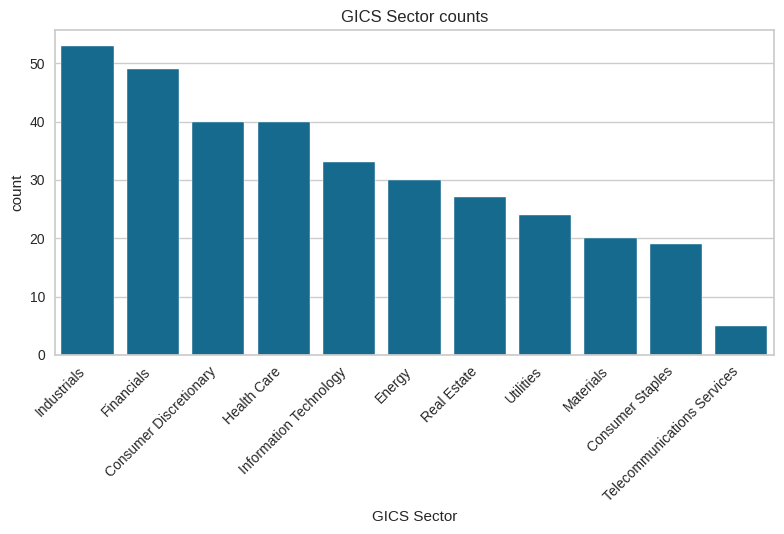

In [16]:
# C14 GICS Sector counts
print(df['GICS Sector'].value_counts().to_string())
sns.countplot(data=df, x='GICS Sector', order=df['GICS Sector'].value_counts().index)
plt.xticks(rotation=45, ha='right')
plt.title('GICS Sector counts')
plt.tight_layout()
plt.show()

###GICS Sub Industry

Rows that will be plotted: 15
GICS Sub Industry
Oil & Gas Exploration & Production                 16
Industrial Conglomerates                           14
REITs                                              14
Electric Utilities                                 12
Internet Software & Services                       12
Health Care Equipment                              11
MultiUtilities                                     11
Banks                                              10
Property & Casualty Insurance                       8
Biotechnology                                       7
Diversified Financial Services                      7
Packaged Foods & Meats                              6
Pharmaceuticals                                     6
Oil & Gas Refining & Marketing & Transportation     6
Semiconductors                                      6


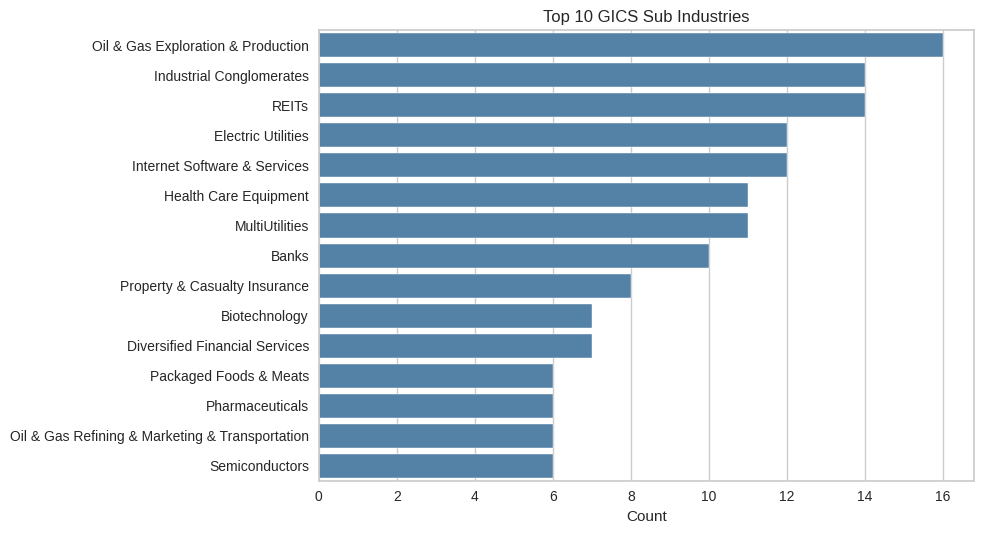

In [17]:
# C15 GICS Sub Industry top 10 (readable)
# Cxx GICS Sub Industry top 10 — clean
top_sub = df['GICS Sub Industry'].value_counts().head(15)

print('Rows that will be plotted:', len(top_sub))
print(top_sub.to_string())

plt.figure(figsize=(10, 5.5))
sns.barplot(x=top_sub.values, y=top_sub.index.astype(str), color='steelblue')
plt.title('Top 10 GICS Sub Industries')
plt.xlabel('Count')
plt.ylabel('')
plt.tight_layout()
plt.show()

GICS Sector
Consumer Discretionary         22
Industrials                    16
Financials                     13
Information Technology         12
Materials                      10
Health Care                     8
Consumer Staples                8
Real Estate                     6
Energy                          4
Utilities                       3
Telecommunications Services     2


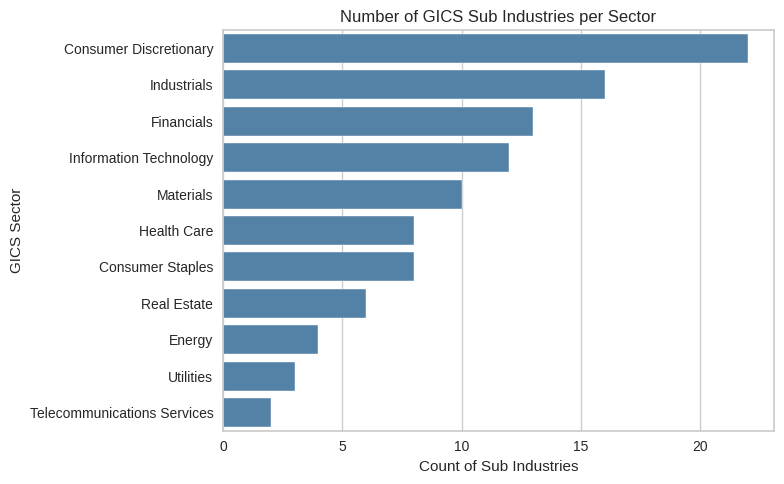

In [18]:
# C16 Sub-industries per sector
sub_per_sector = df.groupby('GICS Sector')['GICS Sub Industry'].nunique().sort_values(ascending=False)
print(sub_per_sector.to_string())

plt.figure(figsize=(8, 5))
sns.barplot(x=sub_per_sector.values, y=sub_per_sector.index.astype(str), color='steelblue')
plt.title('Number of GICS Sub Industries per Sector')
plt.xlabel('Count of Sub Industries')
plt.tight_layout()
plt.show()

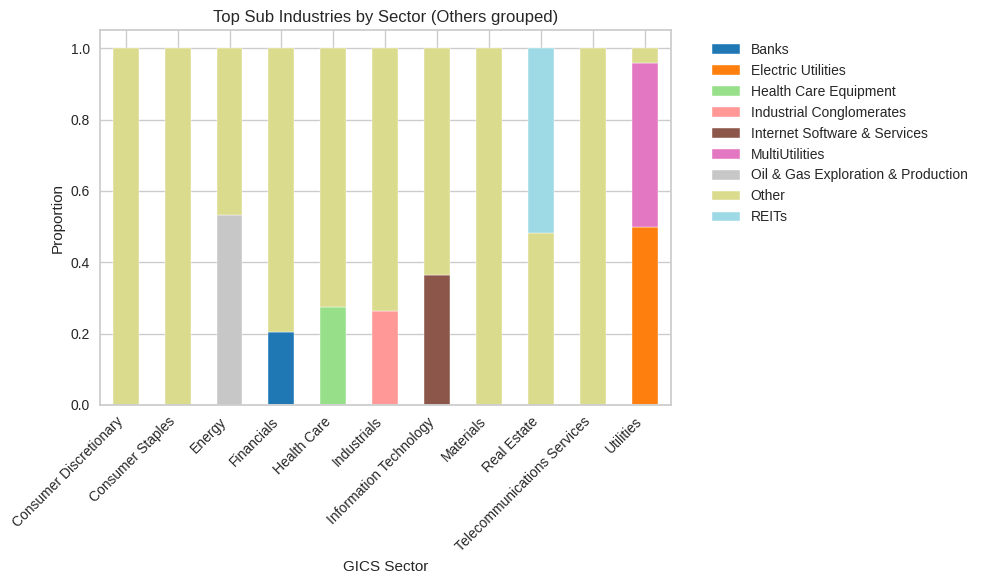

In [19]:
# C17 Top sub-industries by sector

top_subs = df['GICS Sub Industry'].value_counts().head(8).index

df_plot = df.copy()
df_plot['Sub Industry Group'] = (
    df_plot['GICS Sub Industry']
    .astype(str)
    .where(df_plot['GICS Sub Industry'].isin(top_subs), 'Other')
)

tab = pd.crosstab(df_plot['GICS Sector'], df_plot['Sub Industry Group'], normalize='index')
tab.plot(kind='bar', stacked=True, figsize=(10, 6), colormap='tab20')
plt.title('Top Sub Industries by Sector (Others grouped)')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

###Ticker Symbol and Security


In [20]:
# C18 Drop Ticker Symbol and Security
# df_backup keeps the original names so you can join them back to the cluster labels for the final profiles.
print("Before:")
print(df.describe(include='category').T)

df = df.drop(columns=["Ticker Symbol", "Security"])

print("\nAfter:")
print(df.describe(include='category').T)
print(df.shape)

Before:
                  count unique                                 top freq
Ticker Symbol       340    340                                 ZTS    1
Security            340    340                           eBay Inc.    1
GICS Sector         340     11                         Industrials   53
GICS Sub Industry   340    104  Oil & Gas Exploration & Production   16

After:
                  count unique                                 top freq
GICS Sector         340     11                         Industrials   53
GICS Sub Industry   340    104  Oil & Gas Exploration & Production   16
(340, 13)


##Numerical histograms

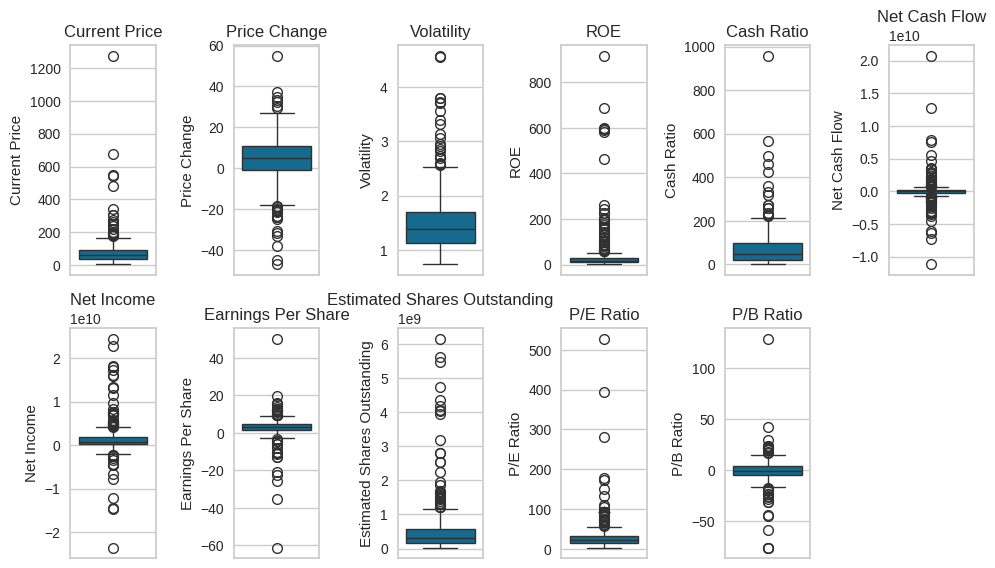

In [21]:
#C19
# a compact overview of numeric data
num_cols = df.select_dtypes(include='number').columns

plt.figure(figsize=(10, 20))
for i, feature in enumerate(num_cols):
    plt.subplot(7, 6, i + 1)
    sns.boxplot(df[feature])
    plt.tight_layout()
    plt.title(feature)
plt.show()


###Current Price

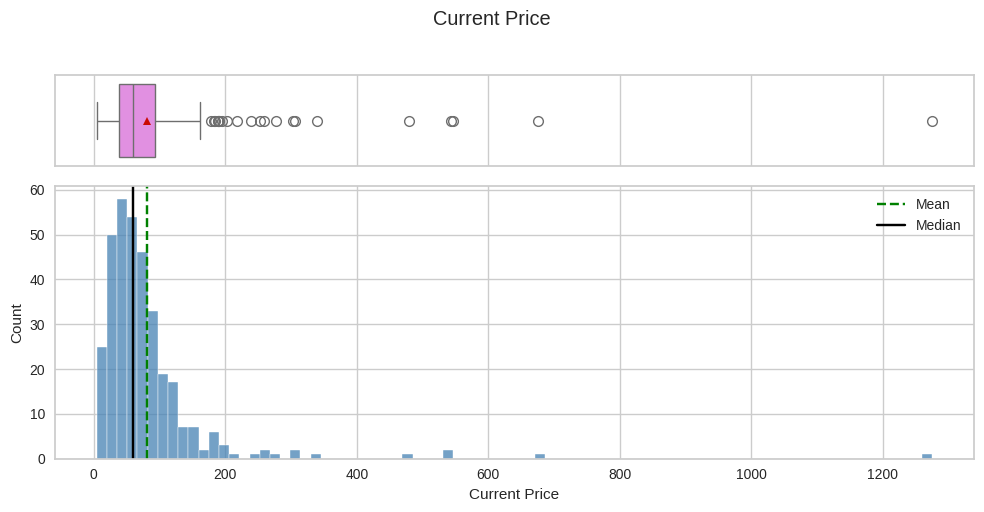

count    340.00
mean      80.86
std       98.06
min        4.50
25%       38.55
50%       59.70
75%       92.88
max     1274.95
Skew for Current Price: 7.05
Skew direction is:  right
***********************



In [22]:
#C19
histogram_boxplot(df, "Current Price")

Current Price Summary:

Right-skewed (mean > median).

Most stocks sit below ~100.

Long right tail with several outliers above 200 and one extreme near 1,275.

###Price Change

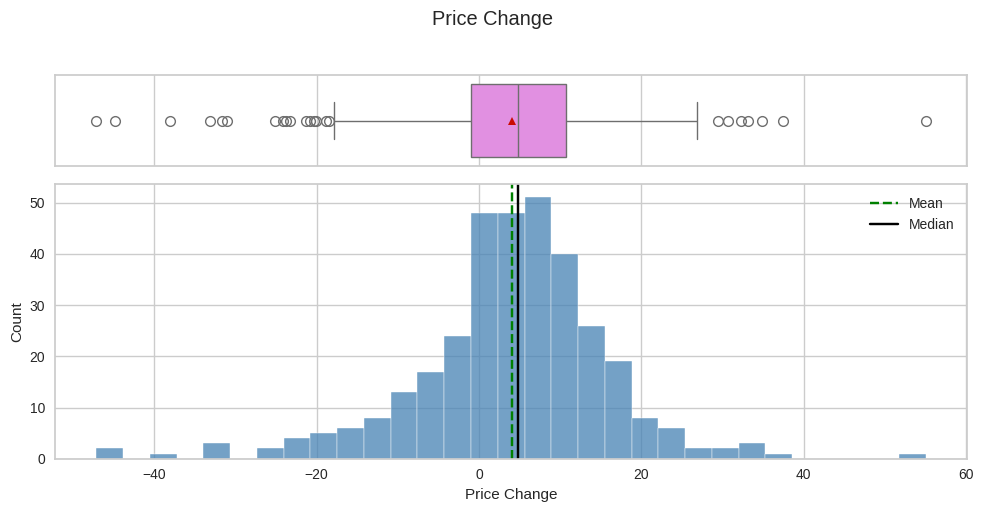

count   340.00
mean      4.08
std      12.01
min     -47.13
25%      -0.94
50%       4.82
75%      10.70
max      55.05
Skew for Price Change: -0.56
Skew direction is:  left
***********************



In [23]:
#C20
histogram_boxplot(df, "Price Change")

Price Change summary:

 Mean 4.08, median 4.82

 Skew –0.56 (mild left skew)

 Range –47.13 to 55.05

 Most values sit between roughly –1 and 11, with a few large positive and negative outliers.

###Volatility

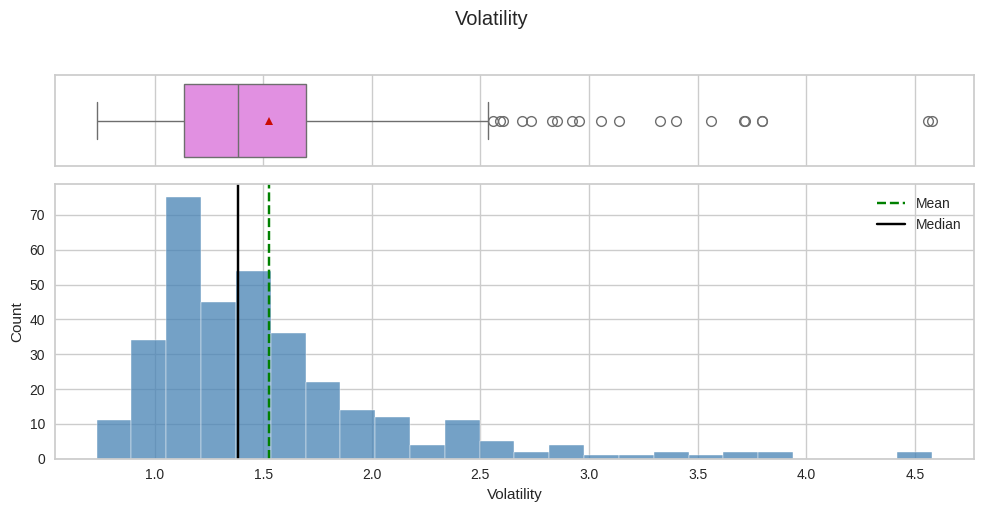

count   340.00
mean      1.53
std       0.59
min       0.73
25%       1.13
50%       1.39
75%       1.70
max       4.58
Skew for Volatility: 2.10
Skew direction is:  right
***********************



In [24]:
#C21
histogram_boxplot(df, "Volatility")

Volatility is right-skewed.

Most stocks sit between roughly 1.0 and 1.7.

Mean is pulled above the median by the right tail.

A few outliers extend past 3.0 up to about 4.6.

###ROE

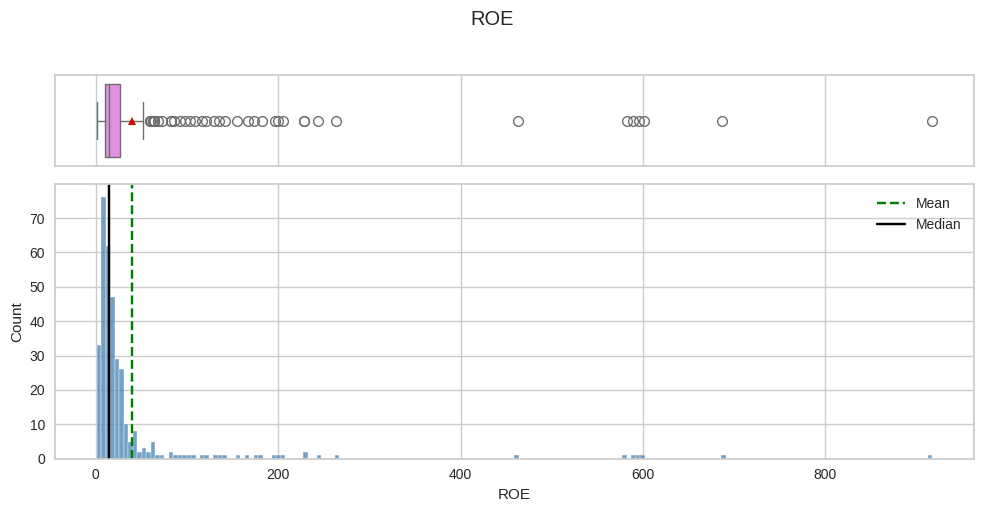

count   340.00
mean     39.60
std      96.55
min       1.00
25%       9.75
50%      15.00
75%      27.00
max     917.00
Skew for ROE: 5.77
Skew direction is:  right
***********************



In [25]:
#C22
histogram_boxplot(df, "ROE")

ROE is extremely right-skewed.

The bulk of the distribution sits below ~30.

Median is low; the mean is pulled far to the right by a long tail.

Extreme outliers reach several hundred (max 917 from the earlier describe).

###Cash Ratio

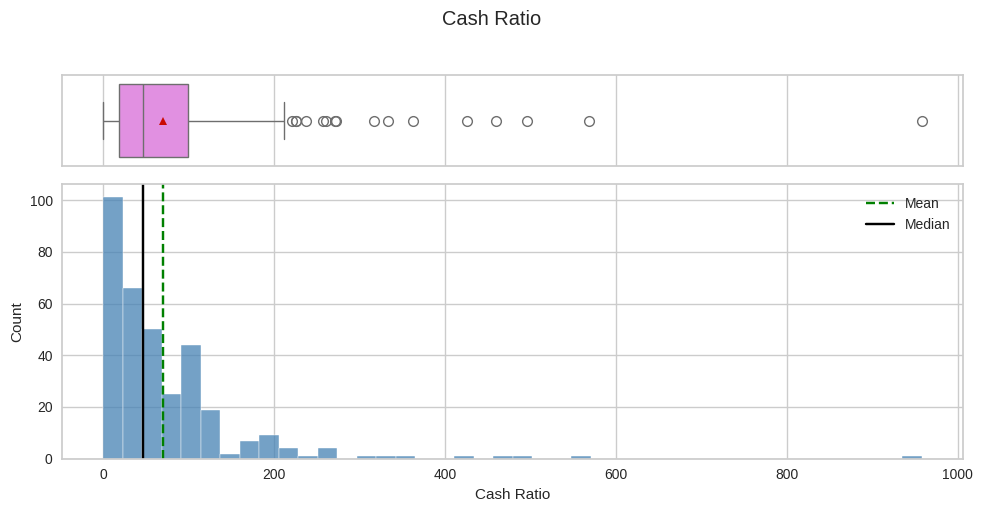

count   340.00
mean     70.02
std      90.42
min       0.00
25%      18.00
50%      47.00
75%      99.00
max     958.00
Skew for Cash Ratio: 4.47
Skew direction is:  right
***********************



In [26]:
#C23
histogram_boxplot(df, "Cash Ratio")

Cash Ratio is right-skewed.

Most stocks sit below ~100.

Median is well below the mean.

A long right tail extends past 400, with one extreme near 960 (matches the earlier max of 958).

###Net Cash Flow

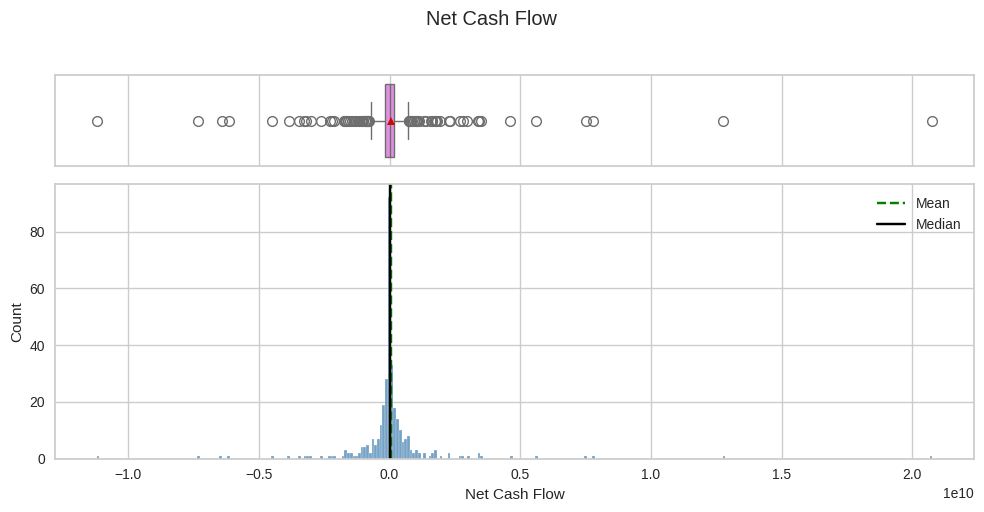

count            340.00
mean        55537620.59
std       1946365312.18
min     -11208000000.00
25%       -193906500.00
50%          2098000.00
75%        169810750.00
max      20764000000.00
Skew for Net Cash Flow: 3.85
Skew direction is:  right
***********************



In [27]:
#C24
histogram_boxplot(df, "Net Cash Flow")

The central mass is tightly concentrated near zero.

Mean > median, so the distribution is right-skewed.

The skew is driven by a few extreme positive outliers (up to ~2e10) that pull the mean to the right of the median.

There are also large negative outliers, but they are fewer/less extreme than the positive side.

###Net Income

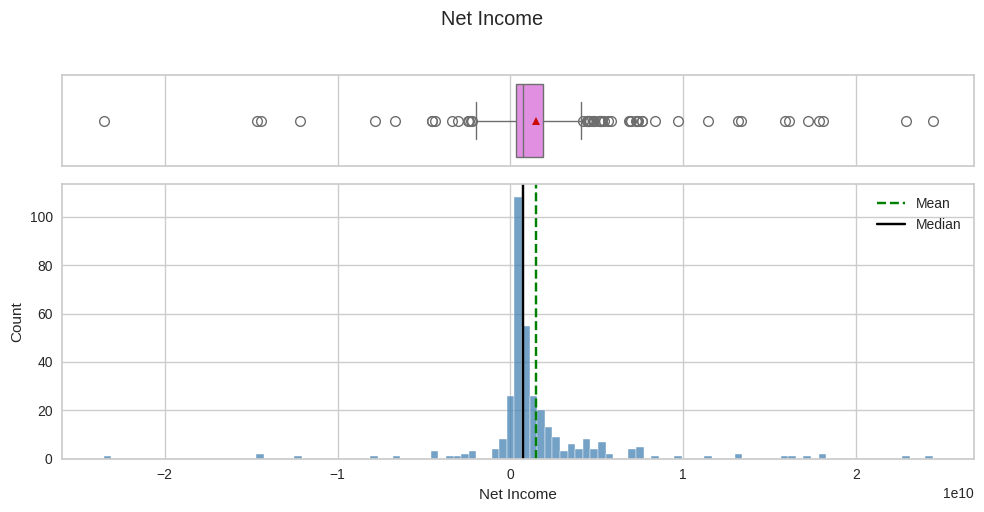

count            340.00
mean      1494384602.94
std       3940150279.33
min     -23528000000.00
25%        352301250.00
50%        707336000.00
75%       1899000000.00
max      24442000000.00
Skew for Net Income: 0.95
Skew direction is:  right
***********************



In [28]:
#C24
histogram_boxplot(df, "Net Income")

Net Income is tightly concentrated near zero with extreme outliers on both sides.

Mean sits slightly to the right of the median → mild right skew.

The central histogram looks nearly symmetric on this scale; the skew is driven by the large positive outliers (up to ~2.4e10).

Large negative outliers are also present but fewer.

###Earnings Per Share

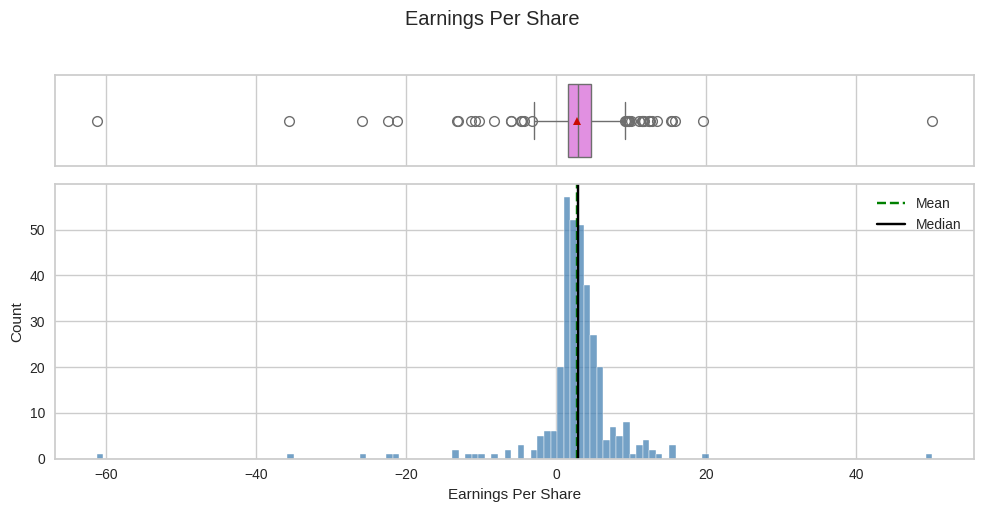

count   340.00
mean      2.78
std       6.59
min     -61.20
25%       1.56
50%       2.90
75%       4.62
max      50.09
Skew for Earnings Per Share: -2.72
Skew direction is:  left
***********************



In [29]:
#C25
histogram_boxplot(df, "Earnings Per Share")

Earnings Per Share is tightly concentrated near zero to about 5, with extreme outliers on both sides.

Mean (2.78) is slightly left of the median (2.90) → mild left skew.

The skew is driven by the long negative tail (down to –61).

Positive outliers exist but are less extreme than the negative ones.

###Estimated Shares Outstanding

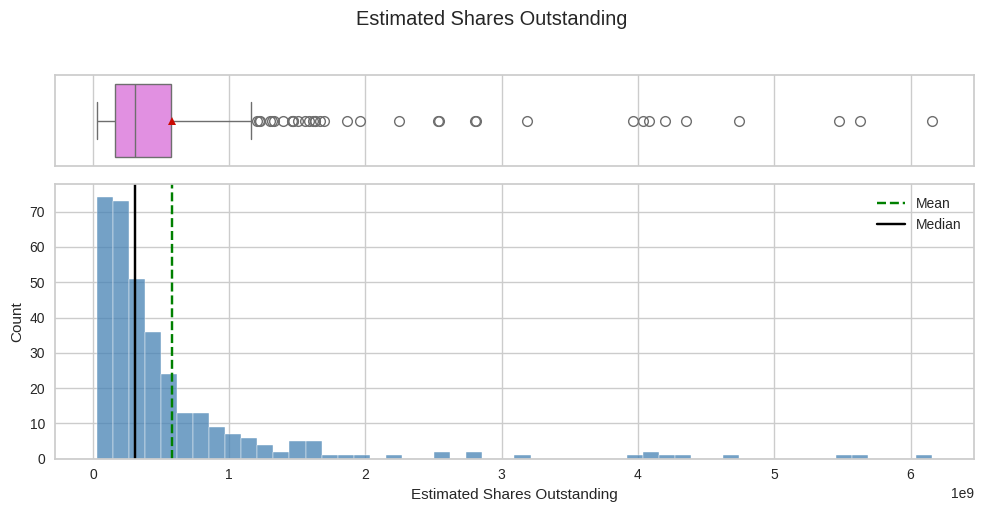

count          340.00
mean     577028337.75
std      845849595.42
min       27672156.86
25%      158848216.10
50%      309675137.80
75%      573117457.32
max     6159292035.00
Skew for Estimated Shares Outstanding: 3.85
Skew direction is:  right
***********************



In [30]:
#C26
histogram_boxplot(df, "Estimated Shares Outstanding")

Estimated Shares Outstanding is right-skewed.

Most stocks have a relatively small number of shares outstanding (bulk below ~0.5e9).

Mean is pulled to the right of the median by the long upper tail.

Extreme outliers extend past 4e9 up to about 6e9.

###P/E Ratio

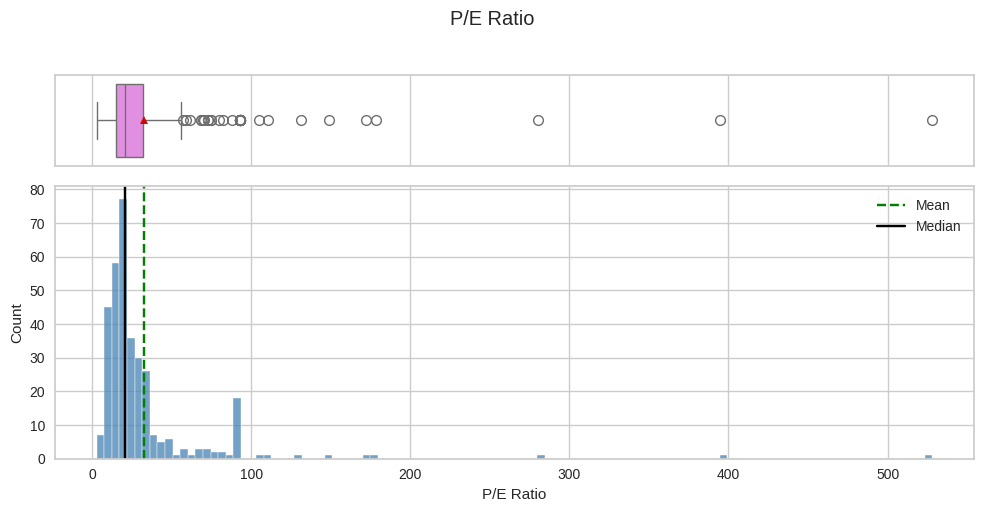

count   340.00
mean     32.61
std      44.35
min       2.94
25%      15.04
50%      20.82
75%      31.76
max     528.04
Skew for P/E Ratio: 6.71
Skew direction is:  right
***********************



In [31]:
#C26
histogram_boxplot(df, "P/E Ratio")

P/E Ratio is right-skewed.

Most stocks sit between roughly 10 and 40.

Mean is pulled above the median by the long upper tail.

Extreme outliers extend past 200 up to about 528 (matches the earlier max).

There is a small secondary bump (mode) around 80–90.

###P/B Ratio

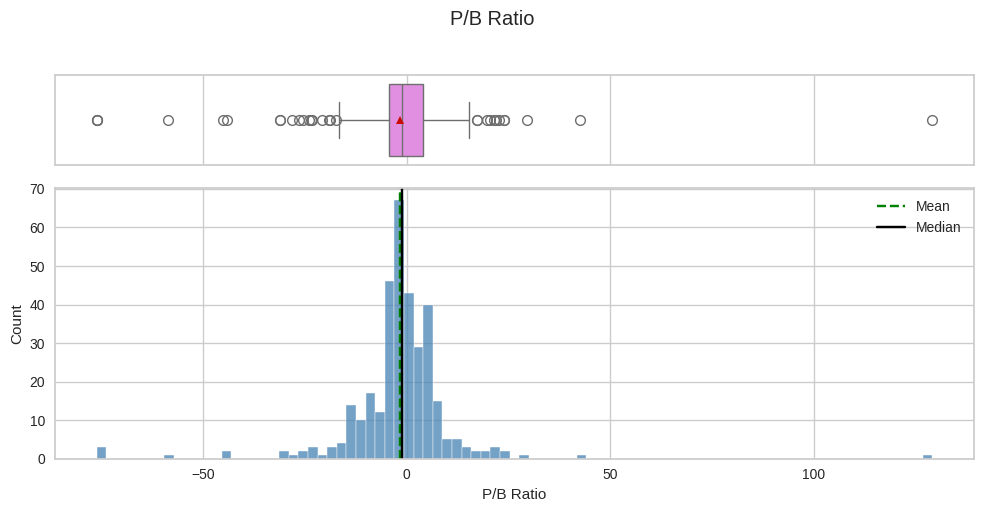

count   340.00
mean     -1.72
std      13.97
min     -76.12
25%      -4.35
50%      -1.07
75%       3.92
max     129.06
Skew for P/B Ratio: 0.82
Skew direction is:  left
***********************



In [32]:
#C27
histogram_boxplot(df, "P/B Ratio")

P/B Ratio is roughly centered near zero.

Mean (–1.72) and median (–1.07) are close → only mild left skew.

The central mass is fairly symmetric.

Extreme outliers exist on both sides (down to about –76 and up to about 129).


##Questions







### 1. What does the distribution of stock prices look like?

- Heavily right-skewed (mean well above median).
- Long upper tail with multiple outliers (max ≈ 1,275).
- Standard deviation (≈ 98) exceeds the mean (≈ 81).

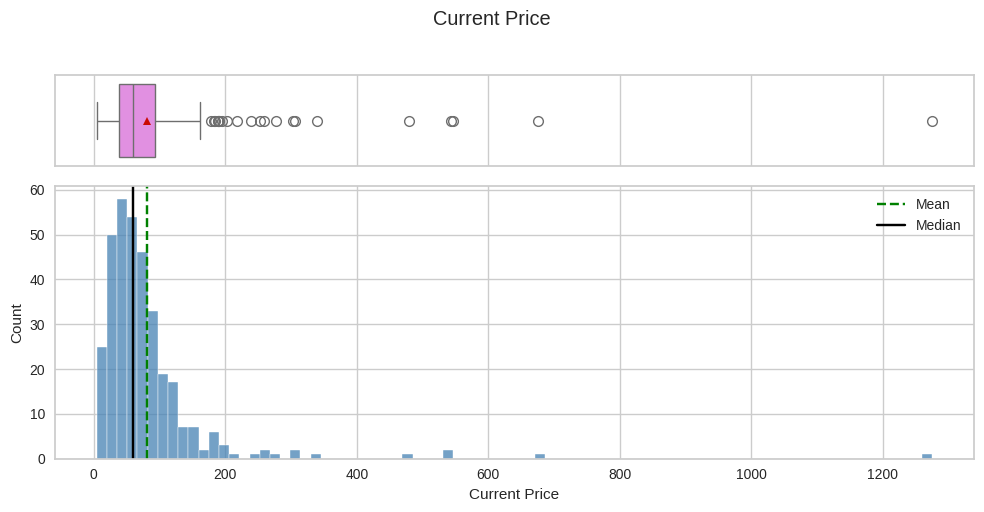

count    340.00
mean      80.86
std       98.06
min        4.50
25%       38.55
50%       59.70
75%       92.88
max     1274.95
Skew for Current Price: 7.05
Skew direction is:  right
***********************



In [33]:
#C28
histogram_boxplot(df, "Current Price")

### 2. The stocks of which economic sector have seen the maximum price increase on average?

- Health Care has the largest average price increase (≈ +9.5).
- Energy has the largest average price decline (≈ –10.2).

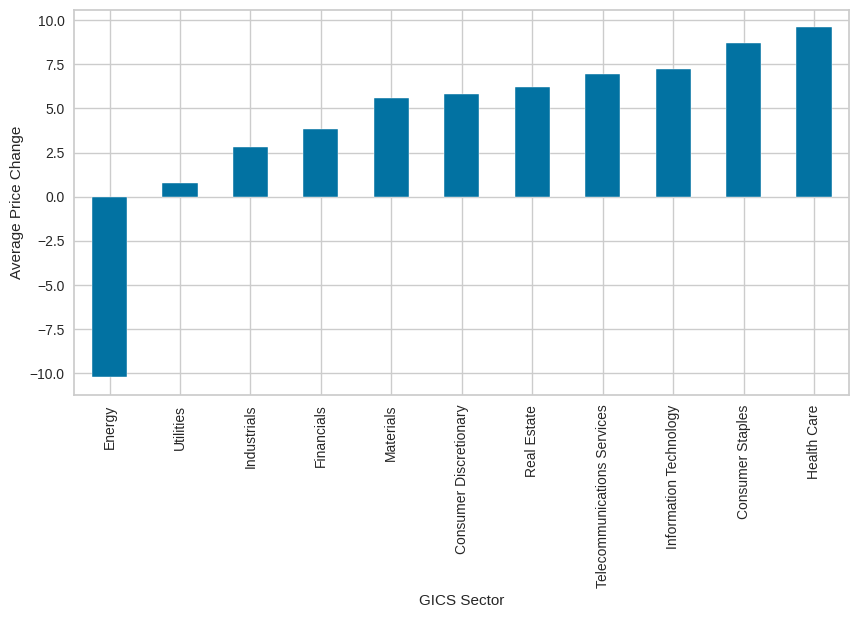

GICS Sector
Energy                        -10.23
Utilities                       0.80
Industrials                     2.83
Financials                      3.87
Materials                       5.59
Consumer Discretionary          5.85
Real Estate                     6.21
Telecommunications Services     6.96
Information Technology          7.22
Consumer Staples                8.68
Health Care                     9.59
Name: Price Change, dtype: float64


In [34]:
#C29
df_tmp=df.groupby('GICS Sector')['Price Change'].mean().sort_values()

ax = df_tmp.plot.bar(figsize=(10, 5), ylabel='Average '+ 'Price Change')
plt.show()
print(df_tmp)

### 3. How are the different variables correlated with each other?

- Volatility is negatively correlated with Price Change (≈ –0.41): higher volatility tends to accompany lower price change.
- Net Income is negatively correlated with Volatility (≈ –0.38).
- Net Income is positively correlated with Earnings Per Share (≈ 0.56).
- Earnings Per Share is positively correlated with Current Price (≈ 0.48).
- Earnings Per Share is negatively correlated with ROE (≈ –0.41).  
  (ROE = Net Income / Equity; the negative link is observed but does not by itself prove a causal story about future returns.)

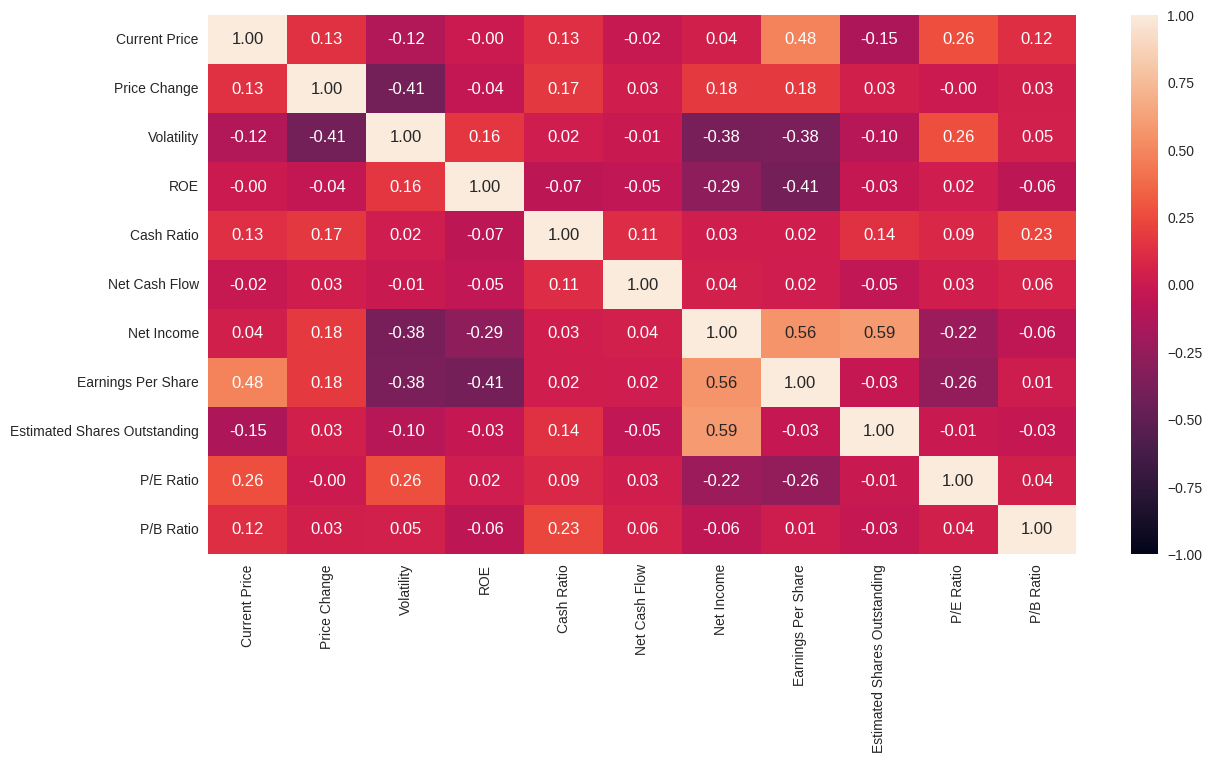

In [35]:
#C30
# create correlation heat map for numerical variables
plt.figure(figsize=(14, 7))
sns.heatmap(
    df[num_cols].corr(),
    annot=True,
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.show()

### 4. How does the average cash ratio vary across economic sectors?

- Information Technology and Telecommunications Services have the highest average cash ratios.
- Utilities has the lowest average cash ratio.
- (Inference) More heavily regulated sectors such as Utilities tend to hold less cash, but the chart alone does not prove causation.

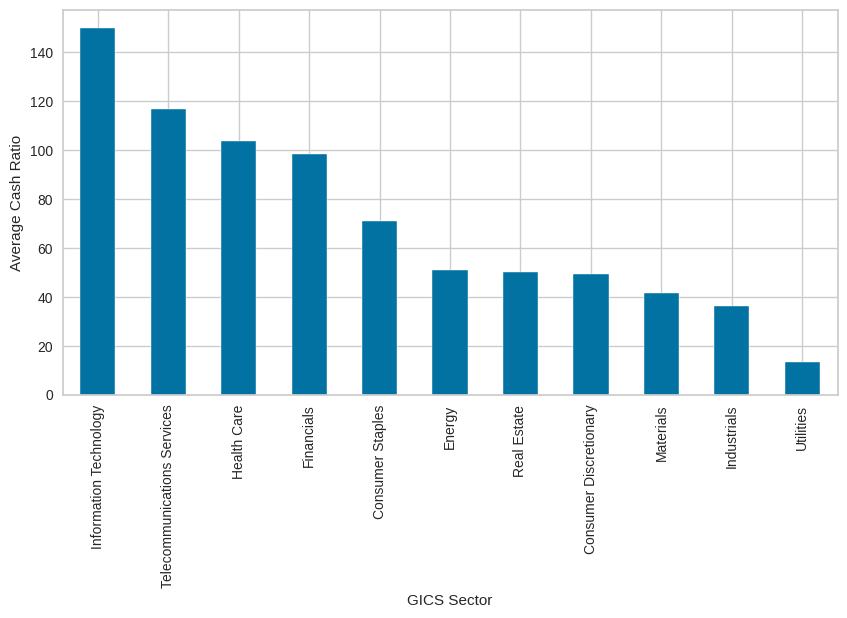

GICS Sector
Information Technology        149.82
Telecommunications Services   117.00
Health Care                   103.78
Financials                     98.59
Consumer Staples               70.95
Energy                         51.13
Real Estate                    50.11
Consumer Discretionary         49.58
Materials                      41.70
Industrials                    36.19
Utilities                      13.62
Name: Cash Ratio, dtype: float64


In [36]:
#C31
df_tmp=df.groupby('GICS Sector')['Cash Ratio'].mean().sort_values(ascending=False)

ax = df_tmp.plot.bar(figsize=(10, 5), ylabel='Average ' + 'Cash Ratio')
plt.show()
print(df_tmp)

### 5. P/E ratios can help determine the relative value of a company's shares as they signify the amount of money an investor is willing to invest in a single share of a company per dollar of its earnings. How does the P/E ratio vary, on average, across economic sectors?
* Energy companies have the largest price to earnings ratio

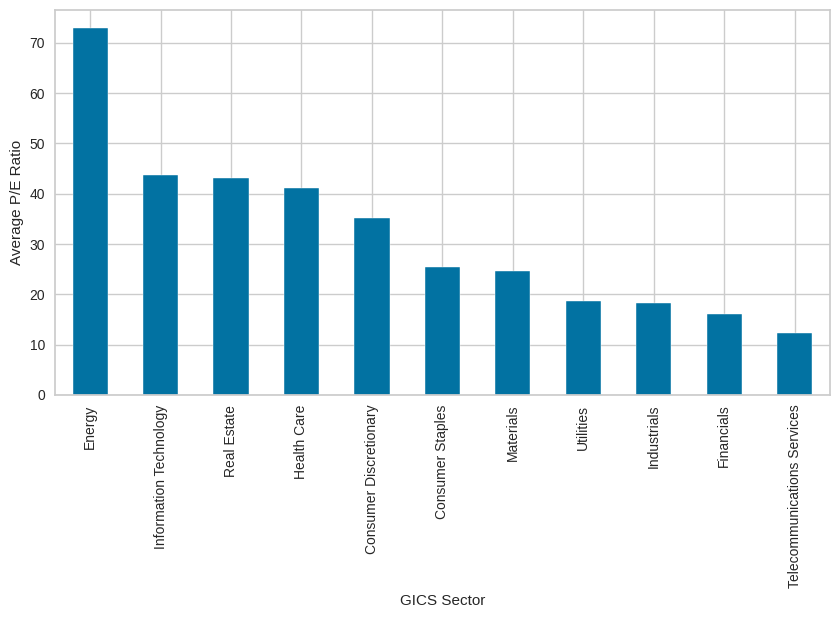

GICS Sector
Energy                        72.90
Information Technology        43.78
Real Estate                   43.07
Health Care                   41.14
Consumer Discretionary        35.21
Consumer Staples              25.52
Materials                     24.59
Utilities                     18.72
Industrials                   18.26
Financials                    16.02
Telecommunications Services   12.22
Name: P/E Ratio, dtype: float64


In [37]:
#C32
df_tmp=df.groupby('GICS Sector')['P/E Ratio'].mean().sort_values(ascending=False)

ax = df_tmp.plot.bar(figsize=(10, 5), ylabel='Average ' + 'P/E Ratio')
plt.show()
print(df_tmp)

# Data Preprocessing

- Duplicate value check
  * Prior checks reveal no duplicated
- Missing value treatment
  * Prior checks reveal no missing values
- Outlier check
  * Prior check reveal outliers add value so no treatment is required.
- Feature engineering (if needed)
  * None noted
- Any other preprocessing steps (if needed)

# K-means Clustering

In [38]:
#C33
# scale the data set before clustering
scaler = StandardScaler()
subset = df[num_cols].copy()
subset_scaled = scaler.fit_transform(subset)

In [39]:
#C34
# create a dataframe from the scaled data
subset_scaled_df = pd.DataFrame(subset_scaled, columns=subset.columns)

subset_scaled_df now holds the z-scored numeric columns with their original names. It is ready for K-means, Hierarchical clustering, and later cluster profiling.

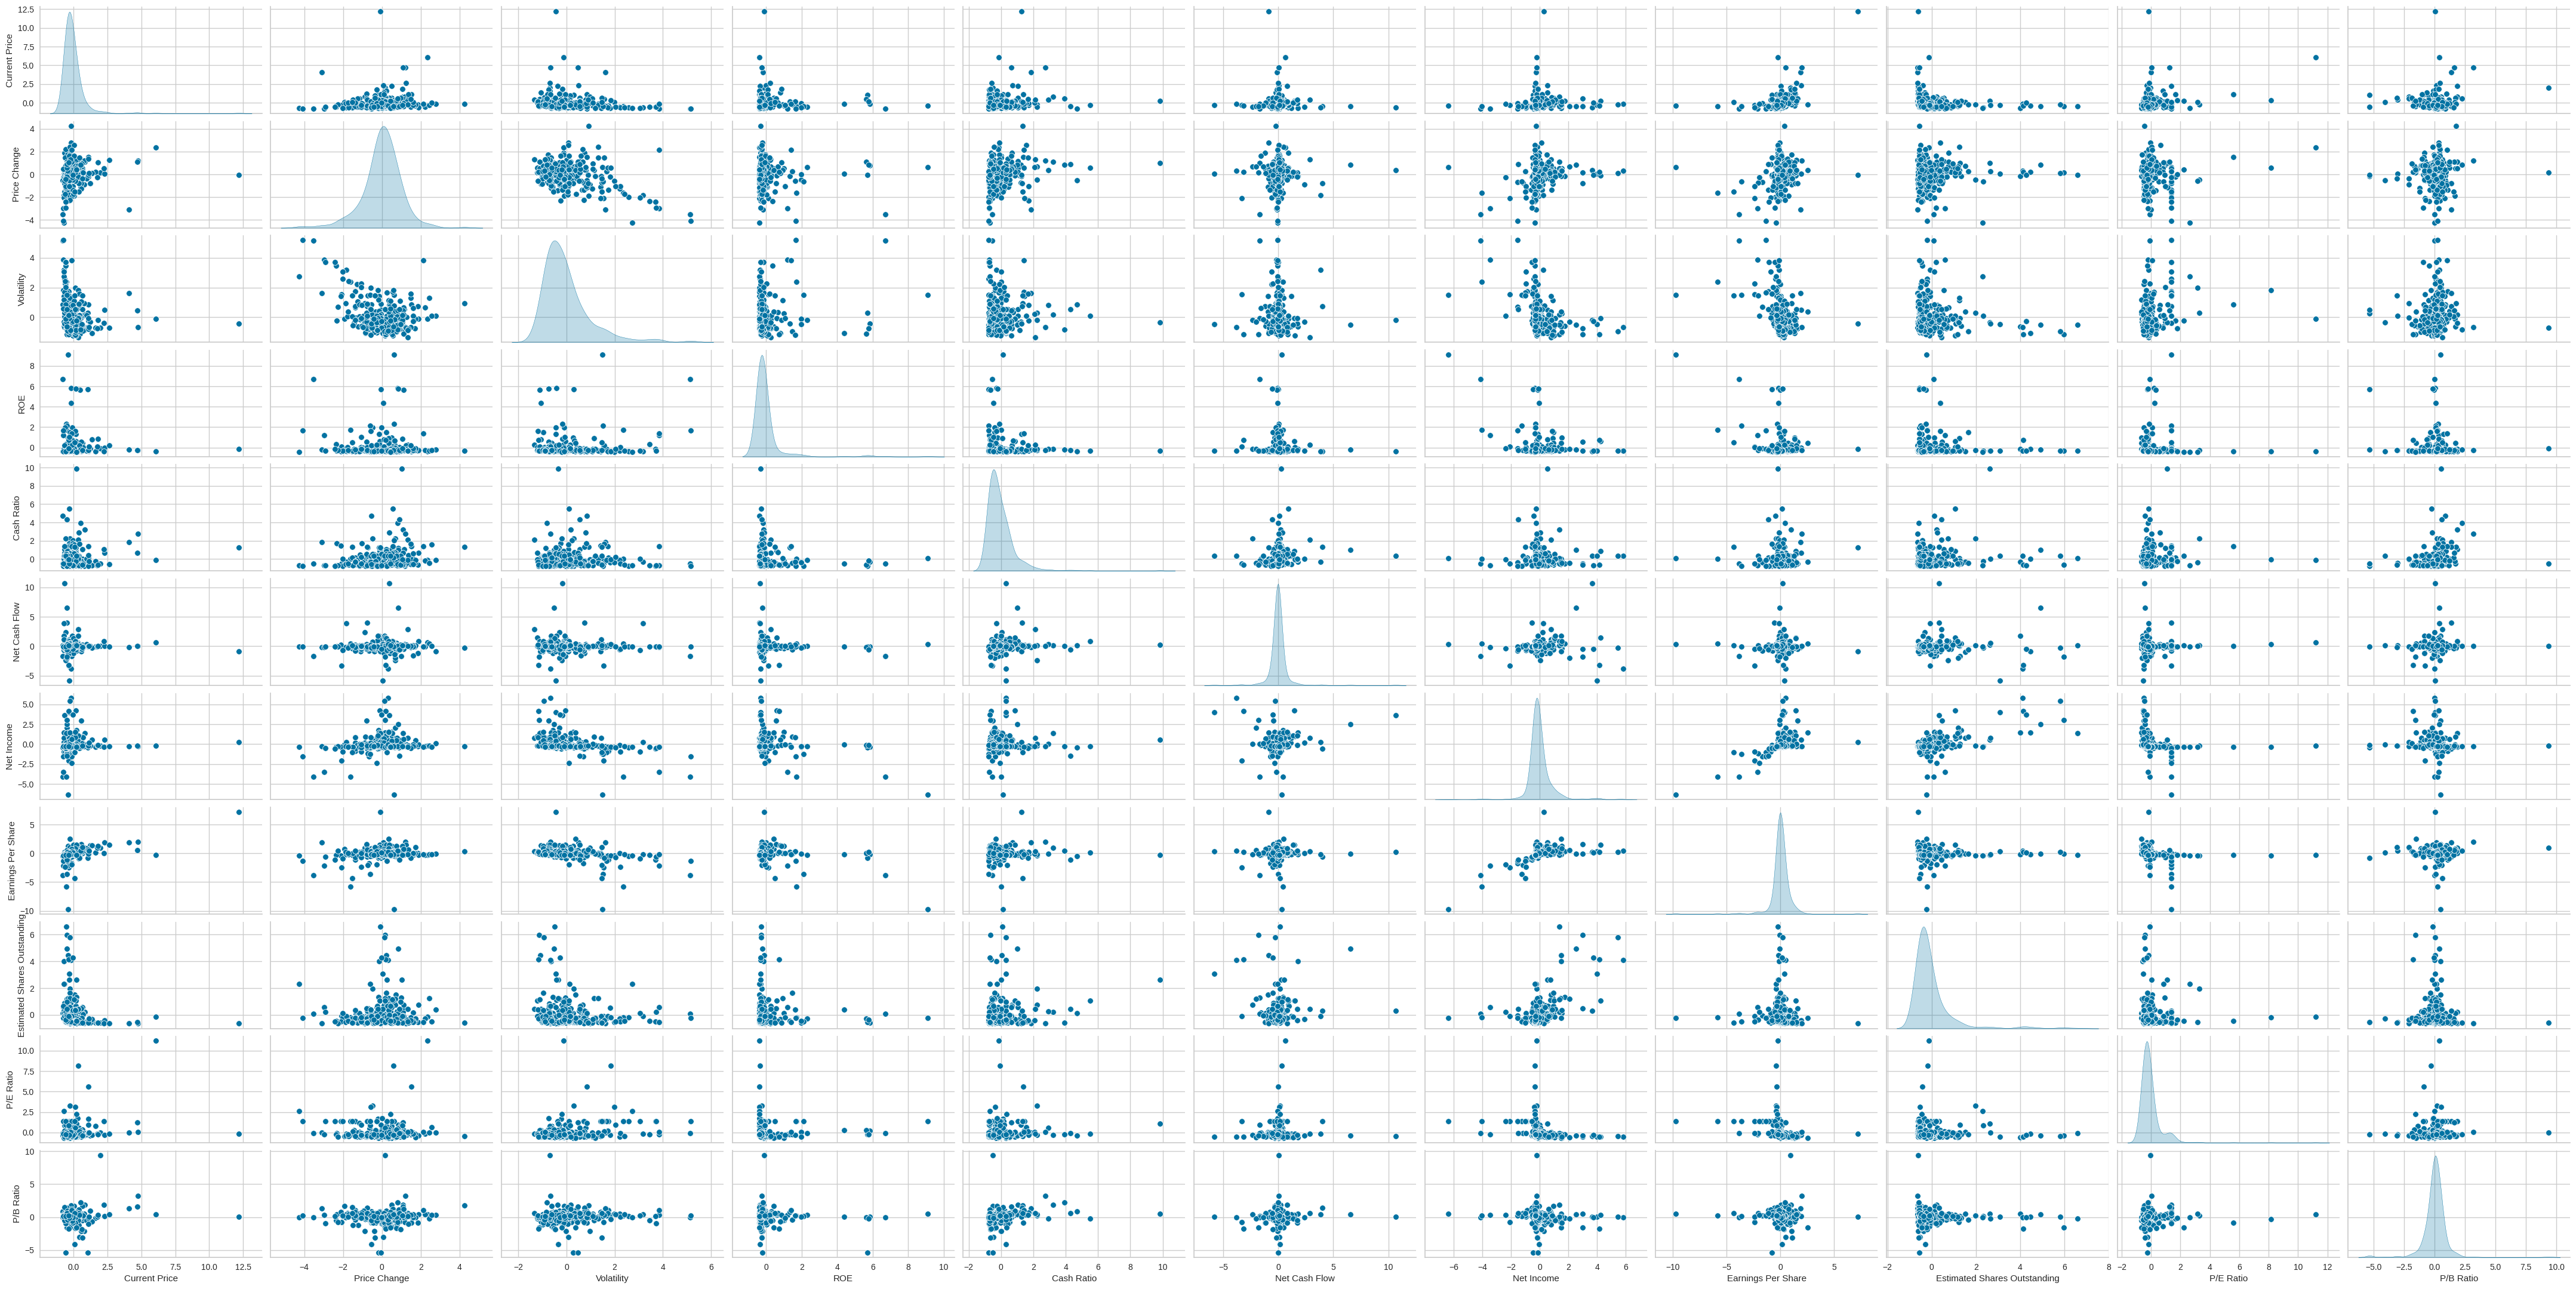

In [40]:
#C35
# create pairplot for scaled dataframe
sns.pairplot(subset_scaled_df, height=2,aspect=2 , diag_kind='kde')
plt.show()

In [41]:
#C36
# print average distortions for range of kmeans models fitted to scaled dataset
clusters = range(1, 11)
meanDistortions = []

for k in clusters:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(subset_scaled_df)
    prediction = model.predict(subset_scaled_df)
    distortion = (
        sum(
            np.min(cdist(subset_scaled_df, model.cluster_centers_, "euclidean"), axis=1)
        )
        / subset_scaled_df.shape[0]
    )

    meanDistortions.append(distortion)

    print("Number of Clusters:", k, "\tAverage Distortion:", distortion)

Number of Clusters: 1 	Average Distortion: 2.5425069919221697
Number of Clusters: 2 	Average Distortion: 2.382318498894466
Number of Clusters: 3 	Average Distortion: 2.2668604252073914
Number of Clusters: 4 	Average Distortion: 2.175554082632614
Number of Clusters: 5 	Average Distortion: 2.1225218310422096
Number of Clusters: 6 	Average Distortion: 2.0801488338794774
Number of Clusters: 7 	Average Distortion: 2.007912388016502
Number of Clusters: 8 	Average Distortion: 1.9906420980784045
Number of Clusters: 9 	Average Distortion: 1.9238161193330066
Number of Clusters: 10 	Average Distortion: 1.8778525055691633


Distortion declines steadily from 2.54 (k=1) to 1.88 (k=10). No single sharp elbow.

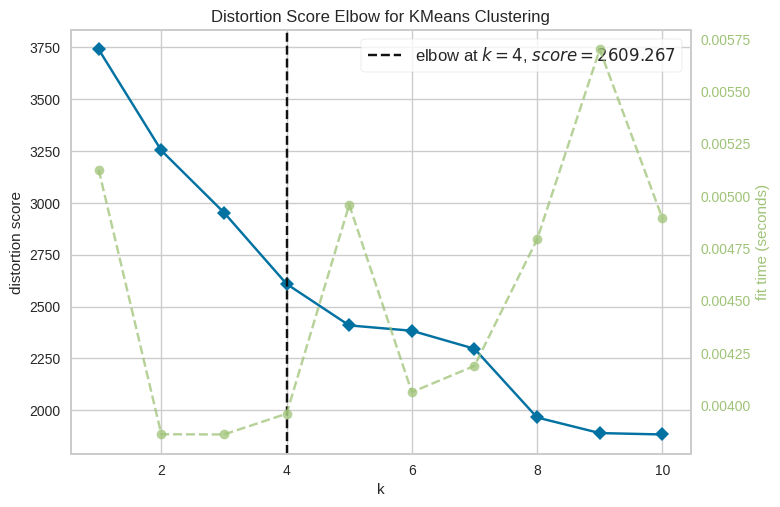

In [42]:
#C37
# fit KMeans model and use visualizaer to indicate optimal K value
model = KMeans(random_state=42)
visualizer = KElbowVisualizer(model, k=(1, 11), timings=True)
visualizer.fit(subset_scaled_df)  # fit the data to the visualizer
visualizer.show()  # finalize and render figure
plt.show()

For n_clusters = 2, the silhouette score is 0.4484662124740991
For n_clusters = 3, the silhouette score is 0.4419662311474576
For n_clusters = 4, the silhouette score is 0.45434371948348606
For n_clusters = 5, the silhouette score is 0.4670141851729817
For n_clusters = 6, the silhouette score is 0.16609442972204497
For n_clusters = 7, the silhouette score is 0.16010466610937854
For n_clusters = 8, the silhouette score is 0.3811731688385819
For n_clusters = 9, the silhouette score is 0.16110839502412727
For n_clusters = 10, the silhouette score is 0.15641849202440433


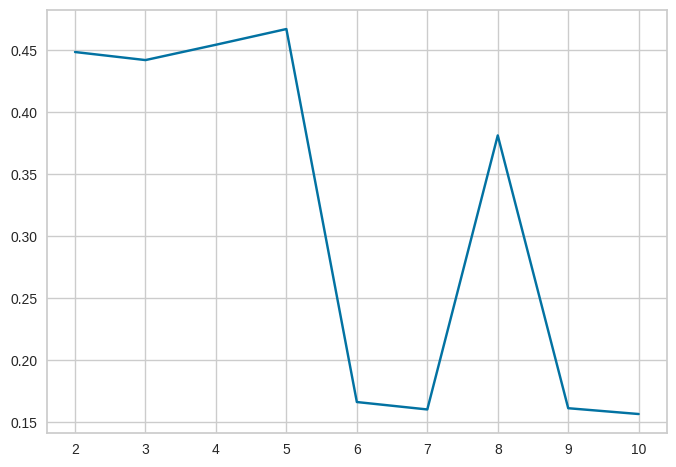

In [43]:
#C38
# fit KMeans model and provide silhouette scores for range of k clusters
sil_score = []
cluster_list = range(2, 11)
for n_clusters in cluster_list:
    clusterer = KMeans(n_clusters=n_clusters, random_state=42)
    preds = clusterer.fit_predict((subset_scaled_df))
    score = silhouette_score(subset_scaled_df, preds)
    sil_score.append(score)
    print("For n_clusters = {}, the silhouette score is {}".format(n_clusters, score))

#show scores in line graph
plt.plot(cluster_list, sil_score)
plt.show()

Silhouette scores:

Highest at k = 5 (0.467)

Next at k = 4 (0.454)

Sharp drop after k = 5

Elbow suggested 4; silhouette prefers 5. Both are reasonable.

We select k = 5 because it gives the cleaner separation by this metric.

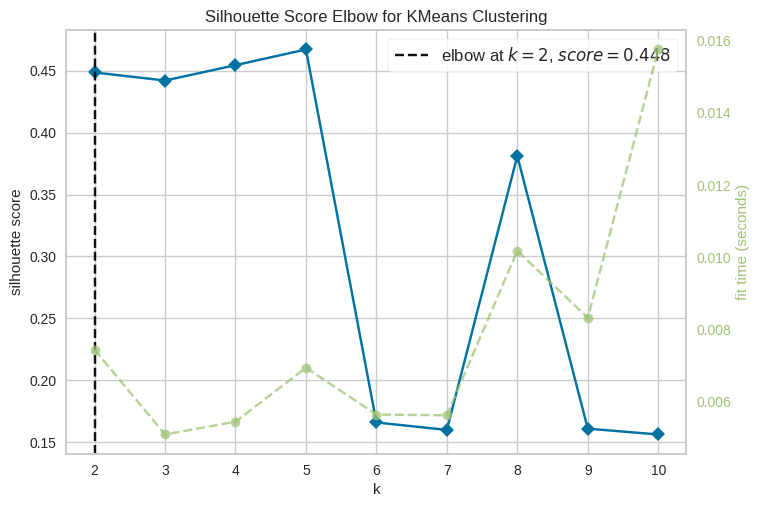

In [44]:
#C39
# fit KMeans model and use visualizaer to indicate optimal K value
model = KMeans(random_state=42)
visualizer = KElbowVisualizer(model, k=(2, 11), metric="silhouette", timings=True)
visualizer.fit(subset_scaled_df)  # fit the data to the visualizer
visualizer.show()  # finalize and render figure
plt.show()

This cell shows Yellowbrick’s silhouette elbow. It does not change the fact that the highest silhouette score is at k = 5. The method is an alternative visual, but the numeric max silhouette remains the clearer signal.

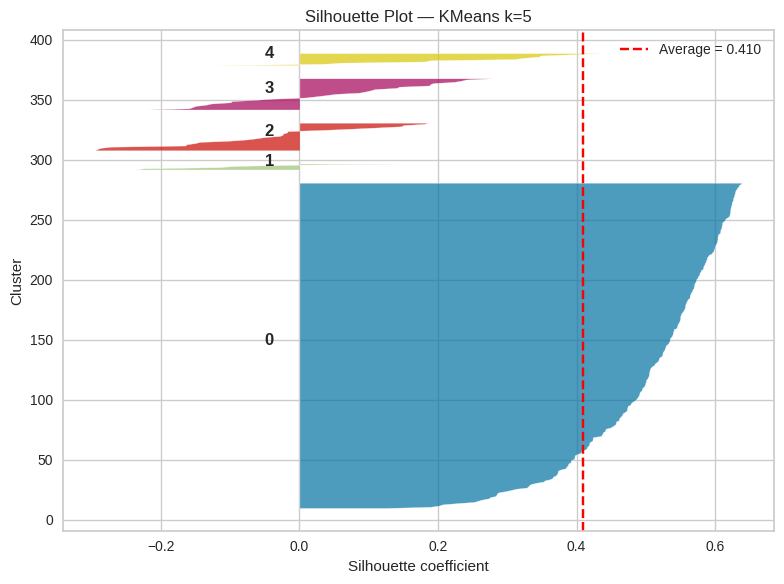

In [45]:
# C40  silhouette plot for k=5
from sklearn.metrics import silhouette_samples

km5 = KMeans(n_clusters=5, random_state=42, n_init=10)
labels = km5.fit_predict(subset_scaled_df)
sil_vals = silhouette_samples(subset_scaled_df, labels)
avg_score = silhouette_score(subset_scaled_df, labels)

fig, ax = plt.subplots(figsize=(8, 6))
y_lower = 10
for i in range(5):
    ith_sil = np.sort(sil_vals[labels == i])
    size = ith_sil.shape[0]
    y_upper = y_lower + size
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_sil, alpha=0.7)
    ax.text(-0.05, y_lower + 0.5 * size, str(i), fontweight="bold")
    y_lower = y_upper + 10

ax.axvline(avg_score, color="red", linestyle="--", label=f"Average = {avg_score:.3f}")
ax.set_xlabel("Silhouette coefficient")
ax.set_ylabel("Cluster")
ax.set_title("Silhouette Plot — KMeans k=5")
ax.legend()
plt.tight_layout()
plt.show()

The best number based on elbow and silhoutte plots is 5. 5 clusters appears optimal.

In [46]:
#C41
# create kmeans cluster model
kmeans = KMeans(n_clusters=5, random_state=42)

#fit model to scaled dataset
print(kmeans.fit(subset_scaled_df))

KMeans(n_clusters=5, random_state=42)


## K Cluster Profile

In [47]:
# C42 add labels and numeric profile
df["KMeans_clusters"] = kmeans.labels_

cluster_profile = df.groupby("KMeans_clusters").mean(numeric_only=True)

cluster_profile["Count"] = (
    df.groupby("KMeans_clusters")["Current Price"].count().values
)

print(cluster_profile.to_string())

                 Current Price  Price Change  Volatility    ROE  Cash Ratio  Net Cash Flow     Net Income  Earnings Per Share  Estimated Shares Outstanding  P/E Ratio  P/B Ratio  Count
KMeans_clusters                                                                                                                                                                         
0                        39.21        -13.77        2.94 109.46       55.32  -157380142.86 -3741645321.43               -9.07                  466855285.55      88.66       1.75     28
1                       536.18          9.58        1.57  15.62      163.62   192455375.00   722016625.00               12.69                  128041091.15     138.98      27.73      8
2                        73.46          5.43        1.40  34.51       55.65   -13418521.28  1470931982.27                3.64                  434059580.68      24.02      -3.18    282
3                        46.67          5.17        1.08  25.00       58.33

In [48]:
#C43
cluster_profile.style.highlight_max(color="lightblue", axis=0)

,Current Price,Price Change,Volatility,ROE,Cash Ratio,Net Cash Flow,Net Income,Earnings Per Share,Estimated Shares Outstanding,P/E Ratio,P/B Ratio,Count
KMeans_clusters,,,,,,,,,,,,
0,39.209643,-13.767941,2.942082,109.464286,55.321429,-157380142.857143,-3741645321.428571,-9.066429,466855285.547857,88.663167,1.747554,28
1,536.179993,9.575377,1.572383,15.625000,163.625000,192455375.000000,722016625.000000,12.693750,128041091.152500,138.982037,27.727469,8
2,73.464376,5.431428,1.397755,34.507092,55.652482,-13418521.276596,1470931982.269504,3.635443,434059580.684787,24.015972,-3.177891,282
3,46.672222,5.166566,1.079367,25.000000,58.333333,-3040666666.666667,14848444444.444445,3.435556,4564959946.222222,15.596051,-6.354193,9
4,74.529488,9.024871,1.537952,24.384615,363.923077,4069216538.461538,4510914000.000000,3.096923,1431070526.361538,44.690616,7.568989,13


| Cluster | Count | Character |
|---------|-------|-----------|
| 0 | 28 | Low price, large price decline, high volatility, negative net income, high P/E → distressed / high-vol |
| 1 | 8 | Very high price (~536), high EPS, high P/E, high P/B, high cash → high-price / growth |
| 2 | 282 | Moderate on everything → broad middle / typical stocks |
| 3 | 9 | Extremely high net income and shares outstanding, low P/E → large profitable companies |
| 4 | 13 | High cash ratio, high net cash flow, high net income → cash-rich |

In [49]:
# C44 company names by KMeans cluster
for cl in sorted(df["KMeans_clusters"].unique()):
    names = df_backup.loc[df["KMeans_clusters"] == cl, "Security"].tolist()
    print(f"Cluster {cl} ({len(names)} companies):")
    print(names)
    print()

Cluster 0 (28 companies):
['Apache Corporation', 'Anadarko Petroleum Corp', 'Baker Hughes Inc', 'Chesapeake Energy', 'Cabot Oil & Gas', 'Concho Resources', 'Devon Energy Corp.', 'EOG Resources', 'EQT Corporation', 'Freeport-McMoran Cp & Gld', 'Hess Corporation', 'Hewlett Packard Enterprise', 'Kinder Morgan', 'Marathon Oil Corp.', 'Murphy Oil', 'Noble Energy Inc', 'Netflix Inc.', 'Newfield Exploration Co', 'National Oilwell Varco Inc.', 'ONEOK', 'Occidental Petroleum', 'Quanta Services Inc.', 'Range Resources Corp.', 'Southwestern Energy', 'Teradata Corp.', 'Williams Cos.', 'Wynn Resorts Ltd', 'Cimarex Energy']

Cluster 1 (8 companies):
['Alliance Data Systems', 'Alexion Pharmaceuticals', 'Amazon.com Inc', 'Chipotle Mexican Grill', 'Equinix', 'Intuitive Surgical Inc.', 'Priceline.com Inc', 'Regeneron']

Cluster 2 (282 companies):
['American Airlines Group', 'AbbVie', 'Abbott Laboratories', 'Adobe Systems Inc', 'Archer-Daniels-Midland Co', 'Ameren Corp', 'American Electric Power', 'AFLAC

| Cluster | Count | Example companies |
|---------|-------|-------------------|
| 0 | 28 | Apache Corporation, Anadarko Petroleum, Chesapeake Energy, Devon Energy, EOG Resources, Hess, Marathon Oil, Occidental Petroleum, Cimarex Energy, Netflix, Wynn Resorts |
| 1 | 8 | Amazon.com, Alexion Pharmaceuticals, Chipotle Mexican Grill, Equinix, Intuitive Surgical, Priceline.com, Regeneron, Alliance Data Systems |
| 2 | 282 | Broad market (examples): Apple-adjacent names omitted; includes Boeing, Disney, JPMorgan-adjacent, Procter & Gamble, Union Pacific, UnitedHealth, etc. |
| 3 | 9 | Citigroup, Ford Motor, JPMorgan Chase, Coca-Cola, Pfizer, AT&T, Verizon, Wells Fargo, Exxon Mobil |
| 4 | 13 | Analog Devices, Amgen, Bank of America, Celgene, Facebook, Gilead Sciences, Halliburton, Intel, McDonald’s, Monster Beverage, Yahoo |

Cluster 2 contains the large majority of the sample; the full name list is available in the notebook output if needed for the appendix.

In [50]:
#C45
# print number of stocks within each sector for all of the clusters
print("Counts:")
print(pd.crosstab(df["KMeans_clusters"], df["GICS Sector"]).to_string())

print("\nProportions (row %):")
print(
    pd.crosstab(df["KMeans_clusters"], df["GICS Sector"], normalize="index")
    .round(2)
    .to_string()
)

Counts:
GICS Sector      Consumer Discretionary  Consumer Staples  Energy  Financials  Health Care  Industrials  Information Technology  Materials  Real Estate  Telecommunications Services  Utilities
KMeans_clusters                                                                                                                                                                                
0                                     1                 0      22           0            0            1                       3          1            0                            0          0
1                                     3                 0       0           0            3            0                       1          0            1                            0          0
2                                    34                17       6          45           32           52                      25         19           26                            2         24
3                               

| Cluster | Count | Sector mix | Refined character |
|---------|-------|------------|-------------------|
| 0 | 28 | 22 Energy | Energy-heavy, high-vol, negative earnings, price decline |
| 1 | 8 | 3 Discretionary, 3 Health Care, 1 IT, 1 Real Estate | High-price growth / expensive names |
| 2 | 282 | Broad; Industrials 52, Financials 45 largest | Typical / diversified market |
| 3 | 9 | 3 Financials, 2 Telecom + large majors (Exxon, etc.) | Large-cap high-income |
| 4 | 13 | 4 Health Care, 4 IT | Cash-rich (tech / biotech tilt) |

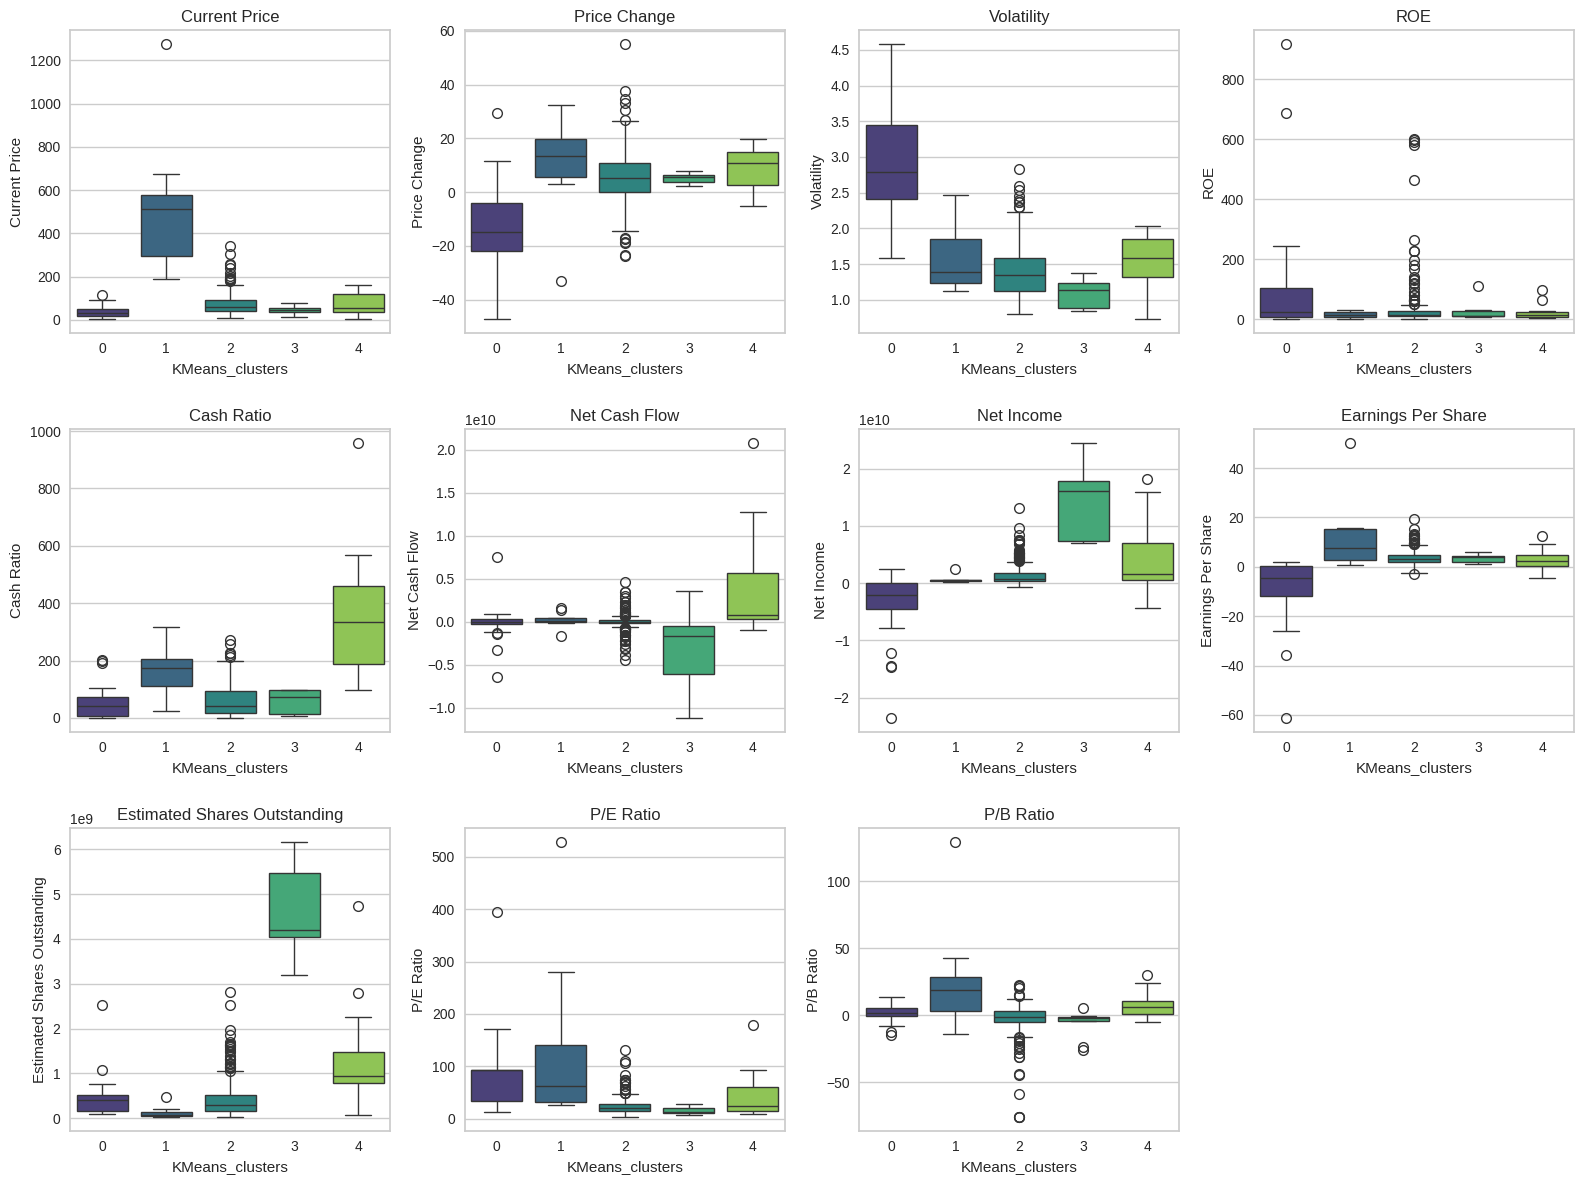

In [51]:
# C46 boxplots by KMeans cluster
# a boxplot of every numeric column, split by the five K-means clusters.
num_cols = [c for c in df.select_dtypes(include='number').columns if c != 'KMeans_clusters']

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df, x='KMeans_clusters', y=col, ax=axes[i], palette='viridis')
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## KMeans Clusters

## Cluster 0 – Energy-heavy, high-volatility, negative earnings

- Count: 28 stocks  
- Sector mix: 22 Energy, plus a few Information Technology, Consumer Discretionary, Materials, and Industrials  
- Examples: Apache Corporation, Anadarko Petroleum, Chesapeake Energy, Devon Energy, EOG Resources, Hess Corporation, Marathon Oil, Occidental Petroleum, Cimarex Energy  

Financial profile (means)  
- Low Current Price (~39)  
- Large negative Price Change (~–13.8)  
- High Volatility (~2.94)  
- Negative Net Income  
- High P/E Ratio (~89)  

Character  
Distressed high-volatility Energy names that have experienced sharp price declines and are generating losses. The group is distinct from the broad market cluster because of its heavy Energy concentration and weak earnings and price performance.

## Cluster 1 – High-price growth / expensive names

- Count: 8 stocks  
- Sector mix: 3 Consumer Discretionary, 3 Health Care, 1 Information Technology, 1 Real Estate  
- Examples: Amazon.com, Alexion Pharmaceuticals, Chipotle Mexican Grill, Equinix, Intuitive Surgical, Priceline.com, Regeneron, Alliance Data Systems  

Financial profile (means)  
- Very high Current Price (~536)  
- Positive Price Change (~+9.6)  
- Moderate Volatility  
- High Earnings Per Share (~12.7)  
- High P/E Ratio (\~139) and high P/B Ratio (\~28)  
- Elevated Cash Ratio (~164)  

Character  
High-priced growth and specialty names. Investors are paying large multiples for these stocks. The group is small and distinct from the broad market cluster.

## Cluster 2 – Typical / diversified market

- Count: 282 stocks  
- Sector mix: Broad; Industrials 52, Financials 45, Consumer Discretionary 34, Health Care 32, Real Estate 26, Information Technology 25, Utilities 24, and smaller counts in the remaining sectors  
- Examples: Boeing, Disney, Procter & Gamble, Union Pacific, UnitedHealth, and the large majority of the sample  

Financial profile (means)  
- Moderate Current Price (~73)  
- Modest positive Price Change (~+5.4)  
- Moderate Volatility (~1.40)  
- Moderate ROE, Cash Ratio, and Earnings Per Share  
- P/E Ratio near the overall median (~24)  

Character  
The broad middle of the market. These stocks show typical values on most financial metrics and span nearly every sector. The group is large because most companies do not exhibit the extreme price, earnings, or cash characteristics that define the smaller clusters.

## Cluster 3 – Large-cap high-income

- Count: 9 stocks  
- Sector mix: 3 Financials, 2 Telecommunications Services, plus one each from Consumer Discretionary, Energy, Consumer Staples, and Health Care  
- Examples: Citigroup, Ford Motor, JPMorgan Chase, Coca-Cola, Pfizer, AT&T, Verizon, Wells Fargo, Exxon Mobil  

Financial profile (means)  
- Moderate Current Price (~47)  
- Modest positive Price Change (~+5.2)  
- Low Volatility (~1.08)  
- Extremely high Net Income  
- Very high Estimated Shares Outstanding  
- Low P/E Ratio (~16)  

Character  
Large, established companies with massive net income and share counts. The group includes major banks, telecoms, and well-known consumer and energy names. These stocks are profitable at scale and trade at relatively modest multiples.

## Cluster 4 – Cash-rich (tech / biotech tilt)

- Count: 13 stocks  
- Sector mix: 4 Health Care, 4 Information Technology, plus one each from Consumer Discretionary, Consumer Staples, Energy, Financials, and Telecommunications Services  
- Examples: Analog Devices, Amgen, Bank of America, Celgene, Facebook, Gilead Sciences, Halliburton, Intel, McDonald’s, Monster Beverage, Yahoo  

Financial profile (means)  
- Moderate Current Price (~75)  
- Positive Price Change (~+9.0)  
- Moderate Volatility (~1.54)  
- Very high Cash Ratio (~364)  
- High Net Cash Flow  
- Elevated Net Income  

Character  
Companies holding large cash balances and generating strong cash inflows, with a tilt toward Health Care and Information Technology. The group is distinct from the broad market cluster because of its elevated cash position.

# Hierarchical Clustering

In [52]:
#C47
#  list of distance metrics
distance_metrics = ["euclidean", "chebyshev", "mahalanobis", "cityblock"]

# list of linkage methods
linkage_methods = ["single", "complete", "average", "weighted"]

high_cophenet_corr = 0
high_dm_lm = [0, 0]

for dm in distance_metrics:
    for lm in linkage_methods:
        Z = linkage(subset_scaled_df, metric=dm, method=lm)
        c, coph_dists = cophenet(Z, pdist(subset_scaled_df))
        print(
            "Cophenetic correlation for {} distance and {} linkage is {}.".format(
                dm.capitalize(), lm, round(c,4)
            )
        )
        print(" ")
        if high_cophenet_corr < c:
            high_cophenet_corr = c
            high_dm_lm[0] = dm
            high_dm_lm[1] = lm

Cophenetic correlation for Euclidean distance and single linkage is 0.9232.
 
Cophenetic correlation for Euclidean distance and complete linkage is 0.7873.
 
Cophenetic correlation for Euclidean distance and average linkage is 0.9423.
 
Cophenetic correlation for Euclidean distance and weighted linkage is 0.8694.
 
Cophenetic correlation for Chebyshev distance and single linkage is 0.9063.
 
Cophenetic correlation for Chebyshev distance and complete linkage is 0.5989.
 
Cophenetic correlation for Chebyshev distance and average linkage is 0.9338.
 
Cophenetic correlation for Chebyshev distance and weighted linkage is 0.9127.
 
Cophenetic correlation for Mahalanobis distance and single linkage is 0.9259.
 
Cophenetic correlation for Mahalanobis distance and complete linkage is 0.7925.
 
Cophenetic correlation for Mahalanobis distance and average linkage is 0.9247.
 
Cophenetic correlation for Mahalanobis distance and weighted linkage is 0.8708.
 
Cophenetic correlation for Cityblock dist

In [53]:
#C48
#  printing the combination of distance metric and linkage method with the highest cophenetic correlation
print(
    "Highest cophenetic correlation is {}, which is obtained with {} distance and {} linkage.".format(
        round(high_cophenet_corr,4), high_dm_lm[0].capitalize(), high_dm_lm[1]
    )
)

Highest cophenetic correlation is 0.9423, which is obtained with Euclidean distance and average linkage.


Highest cophenetic correlation: Euclidean distance + average linkage (0.9423).

Close runners-up:

Chebyshev + average (0.9338)

Cityblock + single (0.9334)

Average linkage with Euclidean is the strongest choice for the dendrogram.

In [54]:
#C49
#  list of linkage methods for euclidean distance metric
linkage_methods = ["single", "complete", "average", "centroid", "ward", "weighted"]

high_cophenet_corr = 0
high_dm_lm = [0, 0]

for lm in linkage_methods:
    Z = linkage(subset_scaled_df, metric="euclidean", method=lm)
    c, coph_dists = cophenet(Z, pdist(subset_scaled_df))
    print(
            "Cophenetic correlation for Euclidean distance and {} linkage is {}.".format(
                lm, round(c,4)
            )
        )
    print(" ")
    if high_cophenet_corr < c:
        high_cophenet_corr = c
        high_dm_lm[0] = "euclidean"
        high_dm_lm[1] = lm

Cophenetic correlation for Euclidean distance and single linkage is 0.9232.
 
Cophenetic correlation for Euclidean distance and complete linkage is 0.7873.
 
Cophenetic correlation for Euclidean distance and average linkage is 0.9423.
 
Cophenetic correlation for Euclidean distance and centroid linkage is 0.9314.
 
Cophenetic correlation for Euclidean distance and ward linkage is 0.7101.
 
Cophenetic correlation for Euclidean distance and weighted linkage is 0.8694.
 


In [55]:
#C50 printing the combination of distance metric and linkage method with the highest cophenetic correlation
print(
    "Highest cophenetic correlation is {}, which is obtained with {} linkage.".format(
        round(high_cophenet_corr,4), high_dm_lm[1]
    )
)

Highest cophenetic correlation is 0.9423, which is obtained with average linkage.


Expanded Euclidean comparison:

Average linkage: 0.9423 (highest)

Centroid: 0.9314

Single: 0.9232

Weighted: 0.8694

Complete: 0.7873

Ward: 0.7101

Average linkage remains the best choice. Centroid is a close second. Ward is noticeably lower on this data.

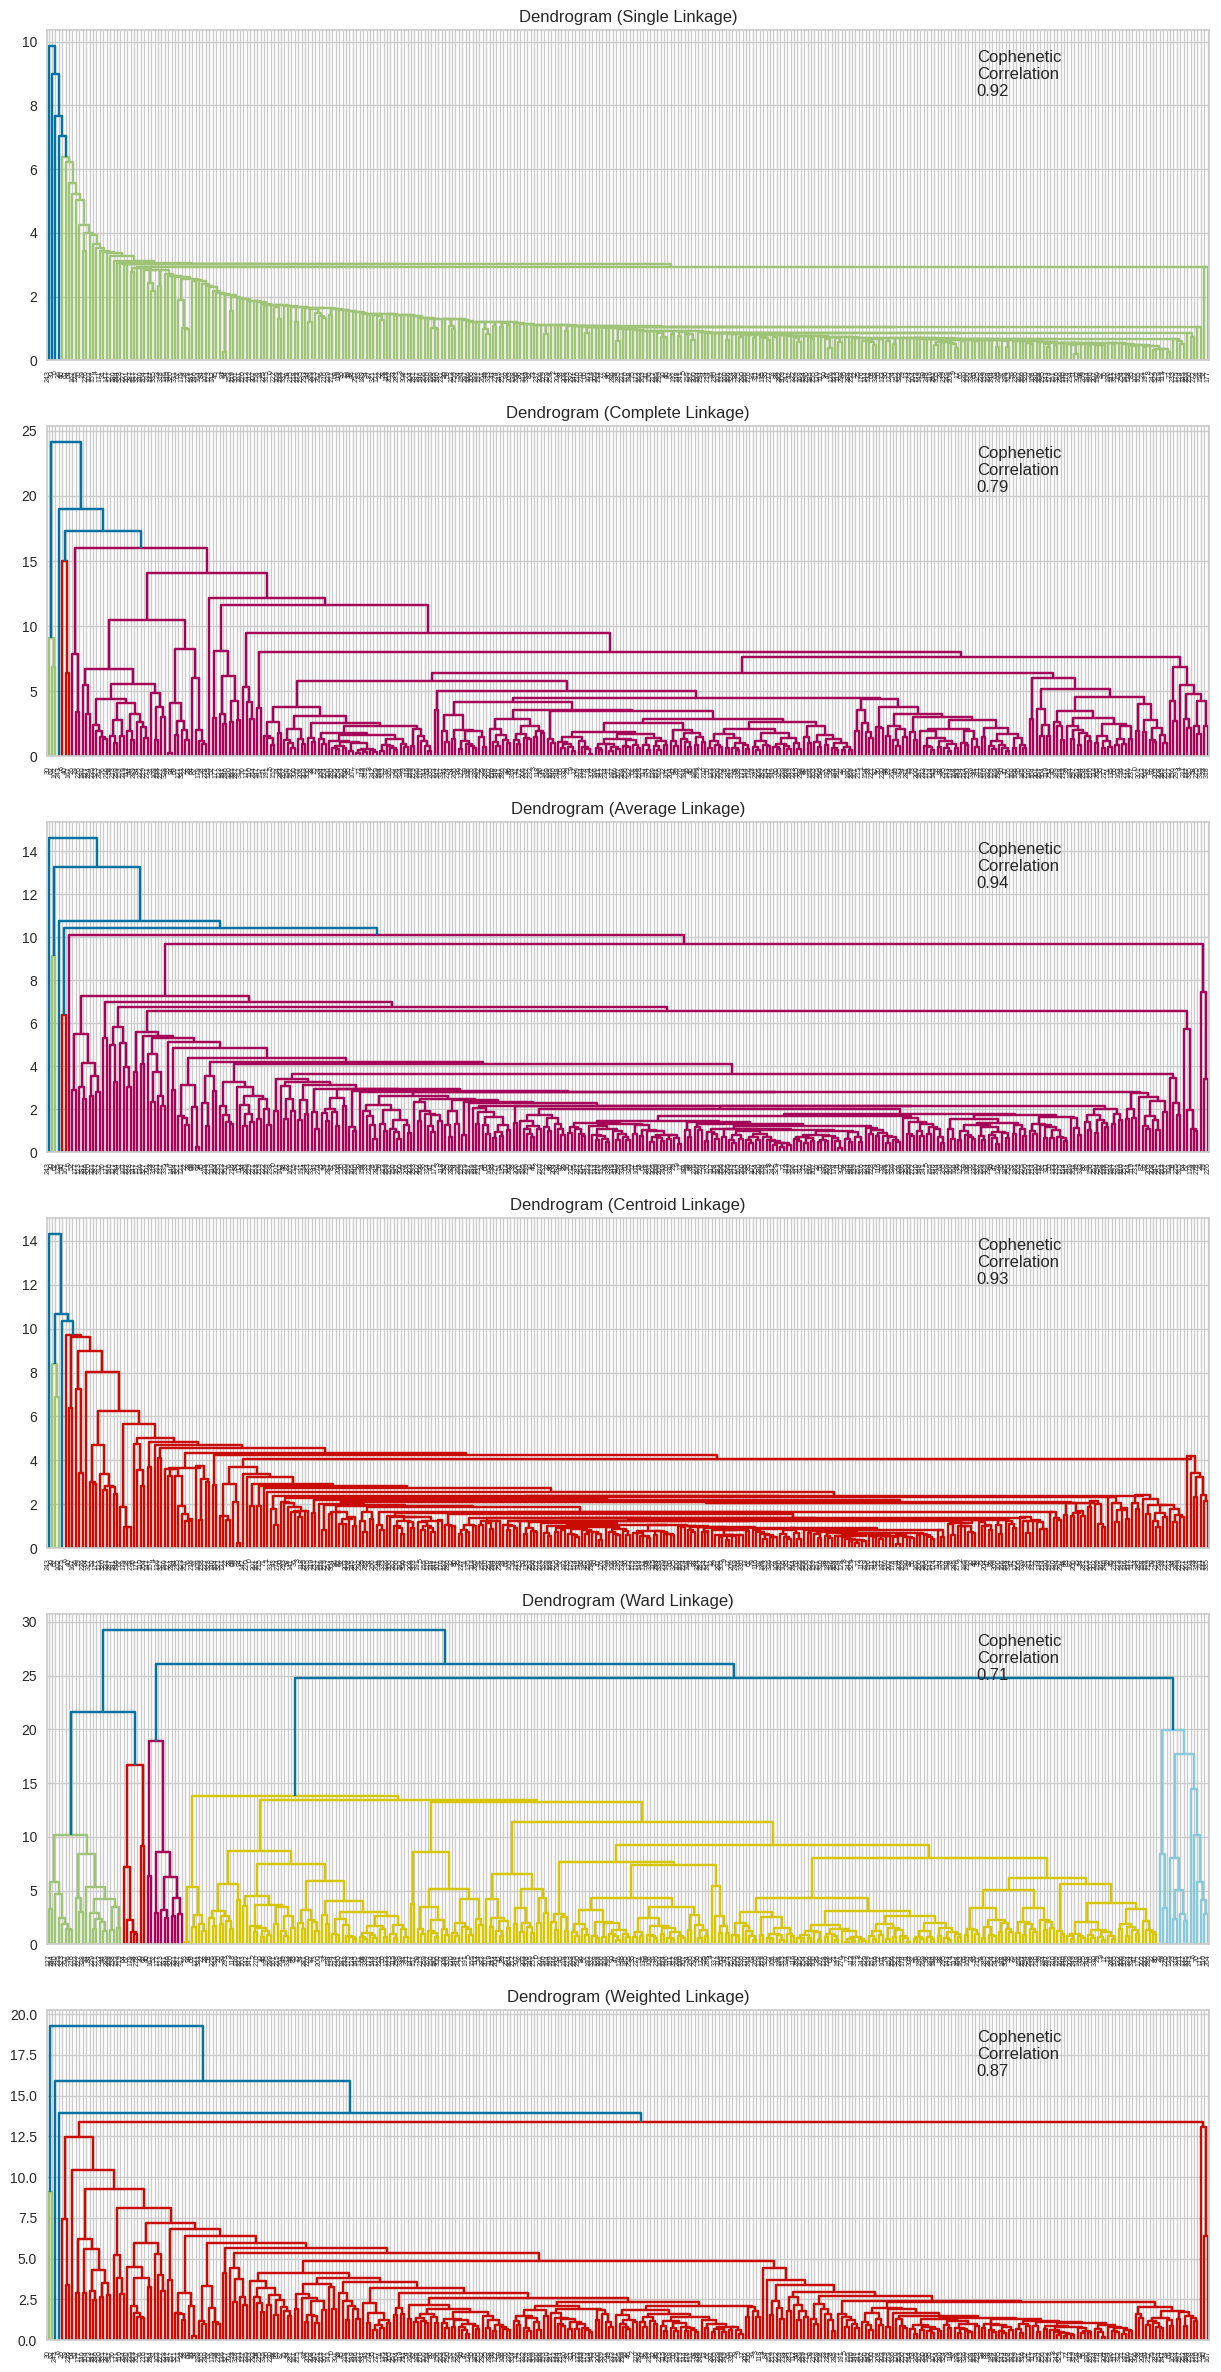

In [56]:
#C51
#  list of linkage methods
linkage_methods = ["single", "complete", "average", "centroid", "ward", "weighted"]

# lists to save results of cophenetic correlation calculation
compare_cols = ["Linkage", "Cophenetic Coefficient"]

# to create a subplot image
fig, axs = plt.subplots(len(linkage_methods), 1, figsize=(15, 30))

# We will enumerate through the list of linkage methods above
# For each linkage method, we will plot the dendrogram and calculate the cophenetic correlation
for i, method in enumerate(linkage_methods):
    Z = linkage(subset_scaled_df, metric="euclidean", method=method)

    dendrogram(Z, ax=axs[i])
    axs[i].set_title(f"Dendrogram ({method.capitalize()} Linkage)")

    coph_corr, coph_dist = cophenet(Z, pdist(subset_scaled_df))
    axs[i].annotate(
        f"Cophenetic\nCorrelation\n{coph_corr:0.2f}",
        (0.80, 0.80),
        xycoords="axes fraction",
    )

The cophenetic correlation is highest for average (0.94) and centroid (0.93) linkage methods under Euclidean distance.

The dendrogram for average linkage shows clearer cluster structure than centroid.

Five clusters appears to be an appropriate cut for the average-linkage dendrogram.

## H Average Linkage Cluster Profile

In [57]:
#C52
Z = linkage(subset_scaled_df, metric='euclidean', method='average')
c, coph_dists = cophenet(Z , pdist(subset_scaled_df))

In [67]:
#C53
hierarchy = AgglomerativeClustering(n_clusters=5, metric='euclidean',  linkage='average')
print(hierarchy.fit(subset_scaled_df))

AgglomerativeClustering(linkage='average', n_clusters=5)


In [59]:
#C54
df_hierarchy = df.copy()
df_hierarchy.drop("KMeans_clusters", axis=1, inplace=True)
df_hierarchy['HC_clusters'] = hierarchy.labels_

In [60]:
# C55 hierarchical cluster profile
cluster_profile_h = df_hierarchy.groupby("HC_clusters").mean(numeric_only=True)

cluster_profile_h["Count"] = (
    df_hierarchy.groupby("HC_clusters")["Current Price"].count().values
)

print(cluster_profile_h.to_string())

             Current Price  Price Change  Volatility    ROE  Cash Ratio  Net Cash Flow      Net Income  Earnings Per Share  Estimated Shares Outstanding  P/E Ratio  P/B Ratio  Count
HC_clusters                                                                                                                                                                          
0                    77.88          4.11        1.52  35.32       66.78   -32825817.37   1535255703.59                2.90                  559027333.15      32.44      -1.78    334
1                    25.64         11.24        1.32  12.50      130.50 16755500000.00  13654000000.00                3.29                 2791829362.10      13.65       1.51      2
2                    24.49        -13.35        3.48 802.00       51.00 -1292500000.00 -19106500000.00              -41.81                  519573983.25      60.75       1.57      2
3                   104.66         16.22        1.32   8.00      958.00   592000000.00   3

There are 2 clusters of one company, 2 clusters of two companies, and a single cluster of the remaining 334 companies

The clustering of these companies does have enough variability

The dendrogram for Ward linkage appears to provide better clustering, with 5 appearing to be the appropriate number of clusters

In [68]:
#C56
HCmodel = AgglomerativeClustering(n_clusters=5, metric="euclidean", linkage="ward")
print(HCmodel.fit(subset_scaled_df))

AgglomerativeClustering(n_clusters=5)


## HC Ward Linkage Cluster Profiling

In [62]:
#C57
subset_scaled_df["HC_clusters"] = HCmodel.labels_
df_hierarchy["HC_clusters"] = HCmodel.labels_

In [63]:
# C58 Ward hierarchical cluster profile
cluster_profile_h = df_hierarchy.groupby("HC_clusters").mean(numeric_only=True)

cluster_profile_h["Count"] = (
    df_hierarchy.groupby("HC_clusters")["Current Price"].count().values
)

print(cluster_profile_h.to_string())

             Current Price  Price Change  Volatility    ROE  Cash Ratio  Net Cash Flow     Net Income  Earnings Per Share  Estimated Shares Outstanding  P/E Ratio  P/B Ratio  Count
HC_clusters                                                                                                                                                                         
0                   326.20         10.56        1.64  14.40      309.47   288850666.67   864498533.33                7.79                  544900261.30     113.10      19.14     15
1                    84.36          3.85        1.83 633.57       33.57  -568400000.00 -4968157142.86              -10.84                  398169036.44      42.28     -11.59      7
2                    42.85          6.27        1.12  22.73       71.45   558636363.64 14631272727.27                3.41                 4242572567.29      15.24      -4.92     11
3                    72.76          5.21        1.43  25.60       60.39    79951512.28  1538594

In [64]:
# C59 company names by Ward HC cluster
for cl in sorted(df_hierarchy["HC_clusters"].unique()):
    names = df_backup.loc[df_hierarchy["HC_clusters"] == cl, "Security"].tolist()
    print(f"Cluster {cl} ({len(names)} companies):")
    print(names)
    print()

Cluster 0 (15 companies):
['Alliance Data Systems', 'Alexion Pharmaceuticals', 'Amgen Inc', 'Amazon.com Inc', 'Chipotle Mexican Grill', 'Equinix', 'Facebook', 'Frontier Communications', 'Intuitive Surgical Inc.', 'Monster Beverage', 'Netflix Inc.', 'Priceline.com Inc', 'Regeneron', 'Waters Corporation', 'Yahoo Inc.']

Cluster 1 (7 companies):
['Allegion', 'Apache Corporation', 'Chesapeake Energy', 'Charter Communications', 'Colgate-Palmolive', 'Kimberly-Clark', 'S&P Global, Inc.']

Cluster 2 (11 companies):
['Bank of America Corp', 'Citigroup Inc.', 'Ford Motor', 'Intel Corp.', 'JPMorgan Chase & Co.', 'Coca Cola Company', 'Pfizer Inc.', 'AT&T Inc', 'Verizon Communications', 'Wells Fargo', 'Exxon Mobil Corp.']

Cluster 3 (285 companies):
['American Airlines Group', 'AbbVie', 'Abbott Laboratories', 'Adobe Systems Inc', 'Analog Devices, Inc.', 'Archer-Daniels-Midland Co', 'Ameren Corp', 'American Electric Power', 'AFLAC Inc', 'American International Group, Inc.', 'Apartment Investment & M

In [65]:
#C60 print the number of stocks in each GICS sector for each cluster
for k in range(0,df_hierarchy['HC_clusters'].nunique()):
    print('The number of stocks within each GICS Sector for Cluster '+str(k)+' are:')
    print(df_hierarchy[df_hierarchy['HC_clusters']==k]['GICS Sector'].value_counts())
    print("   ")

The number of stocks within each GICS Sector for Cluster 0 are:
GICS Sector
Health Care                    5
Information Technology         4
Consumer Discretionary         3
Telecommunications Services    1
Consumer Staples               1
Real Estate                    1
Energy                         0
Industrials                    0
Financials                     0
Materials                      0
Utilities                      0
Name: count, dtype: int64
   
The number of stocks within each GICS Sector for Cluster 1 are:
GICS Sector
Consumer Staples               2
Energy                         2
Consumer Discretionary         1
Financials                     1
Industrials                    1
Health Care                    0
Information Technology         0
Materials                      0
Real Estate                    0
Telecommunications Services    0
Utilities                      0
Name: count, dtype: int64
   
The number of stocks within each GICS Sector for Cluster 2 are

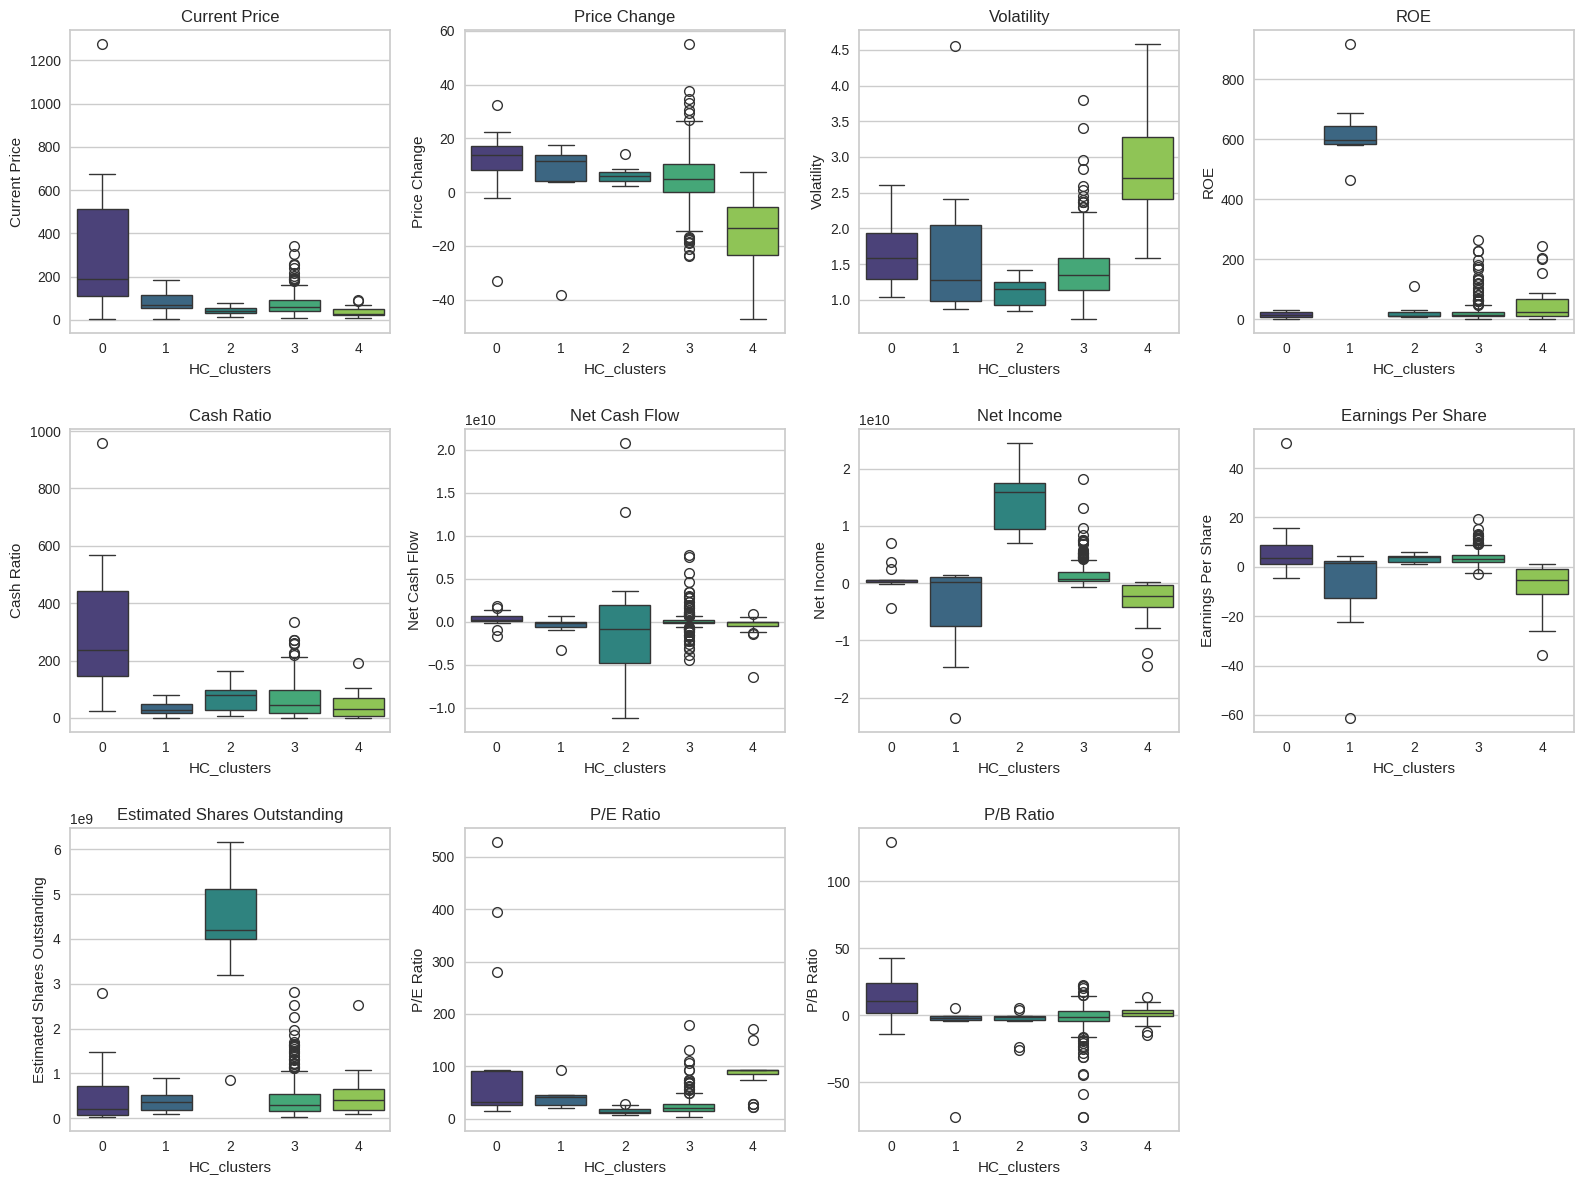

In [66]:
# C61 boxplots by Ward HC cluster
num_cols = [c for c in df_hierarchy.select_dtypes(include='number').columns if c != 'HC_clusters']

fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.ravel()

for i, col in enumerate(num_cols):
    sns.boxplot(data=df_hierarchy, x='HC_clusters', y=col, ax=axes[i], palette='viridis')
    axes[i].set_title(col)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

## Hierarchical Cluster 0 – High-price / high-cash

- Count: 15 stocks  
- Sector mix: (fill from C60 output)  
- Examples: (fill from C59 output)  

Financial profile (means)  
- High Current Price (~326)  
- Positive Price Change (~+10.6)  
- High Cash Ratio (~309)  
- Elevated P/E Ratio (~113) and P/B Ratio (~19)  

Character  
High-priced names with large cash positions and elevated valuation multiples.



## Hierarchical Cluster 1 – Extreme ROE / negative earnings

- Count: 7 stocks  
- Sector mix: (fill from C60)  
- Examples: (fill from C59)  

Financial profile (means)  
- Extreme ROE (~634)  
- Negative Net Income and negative Earnings Per Share  
- Moderate-to-high Volatility  

Character  
Small group of stocks with unusually high ROE but negative earnings.



## Hierarchical Cluster 2 – Large high-income

- Count: 11 stocks  
- Sector mix: (fill from C60)  
- Examples: (fill from C59)  

Financial profile (means)  
- Extremely high Net Income  
- Very high Estimated Shares Outstanding  
- Low P/E Ratio (~15)  

Character  
Large, highly profitable companies with massive share counts.

## Hierarchical Cluster 3 – Typical / diversified market

- Count: 285 stocks  
- Sector mix: Broad  
- Examples: the large majority of the sample  

Financial profile (means)  
- Moderate values on most metrics  
- Modest positive Price Change  

Character  
The broad middle of the market.



## Hierarchical Cluster 4 – Distressed / high-volatility

- Count: 22 stocks  
- Sector mix: (fill from C60)  
- Examples: (fill from C59)  

Financial profile (means)  
- Large negative Price Change (~–16)  
- High Volatility (~2.83)  
- Negative Net Income and negative Earnings Per Share  

Character  
High-volatility names that have experienced sharp price declines and are generating losses.

# K-means vs Hierarchical Clustering

### Which clustering technique took less time for execution?

* Both the KMeans model and the Agglomerative Clustering model fit the dataset within ~0.1s

### Which clustering technique gave you more distinct clusters, or are they the same? How many observations are there in the similar clusters of both algorithms?
* Both algorithms give similar clusters, with a single cluster of a majority of the stocks and the remaining four clusters containing 7-29 stocks

### How many clusters are obtained as the appropriate number of clusters from both algorithms?
* For both algorithms, 5 clusters provided distinct clusters with sufficient observations in each to reasonably differentiate which "type" of stock is representative of the cluster.
**Rule locked:** all tables initially as markdown.

| Method | Large cluster | Smaller clusters |
|--------|---------------|------------------|
| K-means | 282 | 28, 8, 9, 13 |
| Ward HC | 285 | 15, 7, 11, 22 |

### Differences or similarities you obtained in the cluster profiles from both the clustering techniques.

Both algorithms recovered similar themes:
- one large “typical market” cluster
- a distressed / high-volatility group
- a high-price or high-cash group
- a large high-income group

The themes are influenced by the same outliers.

Exact membership and cluster sizes differ between K-means and Ward hierarchical clustering.

# Actionable Insights and Recommendations

1. Trade&Ahead should first identify each client’s financial goals, risk tolerance, and investment horizon, then match the client to one of the clusters as a starting portfolio.

2. The clusters provide distinct building blocks:
   - Cluster 0 (Energy-heavy, high-volatility, negative earnings) for clients who can accept high risk and potential recovery.
   - Cluster 1 (high-price growth) for clients seeking capital appreciation and willing to pay high multiples.
   - Cluster 2 (broad middle) as a diversified core holding.
   - Cluster 3 (large-cap high-income) for clients prioritizing scale and profitability.
   - Cluster 4 (cash-rich, tech/biotech tilt) for clients who want companies with strong cash positions.

3. These clusters can also serve as a screen for further analysis. Stocks that sit far from their cluster’s typical profile (negative silhouette or extreme outliers) are candidates for deeper review before a buy or sell recommendation.

Selecting individual stocks remains part of the client’s strategy. The clusters raise the probability that Trade&Ahead starts with a group whose financial characteristics already match the client’s objectives.